# Problem Statement


Employee Attrition
Employee attrition is a major challenge for organizations because employees leaving the company can increase recruitment and training costs, reduce productivity, and affect overall business performance. Organizations often have difficulty identifying why employees leave and which factors are associated with higher attrition.
This project aims to analyze employee attrition data to identify patterns and factors related to employee turnover, such as age, job role, salary, job satisfaction, overtime, years of experience, work environment, and work-life balance. The analysis can help organizations understand employee behavior and support data-driven strategies for improving employee retention

# Objectives:



1. To analyze employee attrition patterns.

2. To identify the major factors influencing employee attrition.

3. To study the relationship between age, salary, job role,
   and employee attrition.

4. To analyze the impact of job satisfaction and work-life
   balance on employee attrition.

5. To examine the effect of overtime and work environment
   on employee turnover.

6. To identify employee groups with higher attrition rates.

7. To visualize employee attrition data using charts and graphs.

8. To provide data-driven insights for improving employee
   retention.

# Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

 # Data Understanding

In [2]:
df = pd.read_csv('employee_attrition_dataset.csv')
df

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition
0,100405,40,Male,Single,Bachelor,IT,System Admin,1,0,0,...,4,10.8,2,1.9,7.94,White,35,9.7,Bike,No
1,105222,18,Female,Divorced,Master,R&D,Lab Technician,0,0,0,...,3,1.0,0,13.2,10.00,Black,77,7.4,Public Transport,No
2,103358,30,Female,Single,High School,IT,Software Engineer,2,1,1,...,2,11.6,0,18.6,6.65,Yellow,84,8.3,Car,No
3,107337,50,Female,Married,Master,R&D,Research Scientist,1,1,1,...,5,6.1,4,3.9,5.24,Green,27,6.9,Car,Yes
4,108314,28,Male,Married,Bachelor,R&D,Research Scientist,2,1,1,...,6,29.1,0,19.2,7.16,Green,74,7.3,Public Transport,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,105700,18,Male,Married,High School,Operations,Operations Executive,0,0,0,...,5,6.1,0,16.8,7.83,Blue,73,7.1,Car,No
14996,110743,37,Female,Married,Master,IT,IT Manager,5,2,1,...,5,3.4,0,9.5,6.08,Blue,23,8.9,Bike,No
14997,100538,45,Female,Married,NaN,R&D,Research Scientist,4,2,2,...,1,10.6,1,24.1,10.00,Blue,46,8.3,Public Transport,No
14998,109413,30,Female,Married,PhD,Sales,Sales Executive,0,0,0,...,7,1.0,2,10.9,8.50,Green,49,4.6,Walk,Yes


In [3]:
df.shape

(15000, 30)

In [4]:
df.head(10)

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition
0,100405,40,Male,Single,Bachelor,IT,System Admin,1,0,0,...,4,10.8,2,1.9,7.94,White,35,9.7,Bike,No
1,105222,18,Female,Divorced,Master,R&D,Lab Technician,0,0,0,...,3,1.0,0,13.2,10.00,Black,77,7.4,Public Transport,No
2,103358,30,Female,Single,High School,IT,Software Engineer,2,1,1,...,2,11.6,0,18.6,6.65,Yellow,84,8.3,Car,No
3,107337,50,Female,Married,Master,R&D,Research Scientist,1,1,1,...,5,6.1,4,3.9,5.24,Green,27,6.9,Car,Yes
4,108314,28,Male,Married,Bachelor,R&D,Research Scientist,2,1,1,...,6,29.1,0,19.2,7.16,Green,74,7.3,Public Transport,No
5,107717,47,Female,Married,High School,Operations,Operations Executive,3,2,0,...,2,5.8,0,10.0,7.77,Green,59,10.0,Bike,No
6,105944,18,Female,Divorced,Master,Sales,Sales Manager,0,0,0,...,2,24.6,2,21.7,9.87,Red,33,13.4,Car,No
7,114690,48,Female,Divorced,PhD,Operations,Operations Manager,4,2,1,...,1,1.0,0,10.2,4.88,Blue,86,9.8,Public Transport,No
8,100101,32,Male,Married,High School,R&D,R&D Manager,4,3,2,...,3,3.3,1,3.1,10.00,White,10,9.3,Car,No
9,111415,25,Male,Single,High School,IT,System Admin,7,5,5,...,4,7.5,0,13.9,7.39,Red,7,4.4,Car,No


In [5]:
df.tail(10)

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition
14990,111450,30,Female,Single,Bachelor,IT,System Admin,2,1,1,...,0,4.6,1,15.3,3.65,White,32,7.8,Bike,Yes
14991,101373,39,Female,Married,Bachelor,IT,IT Manager,1,0,0,...,6,11.4,1,5.2,7.53,Blue,73,7.4,Public Transport,No
14992,113928,29,Male,Single,Bachelor,R&D,Lab Technician,4,3,2,...,1,4.5,2,11.3,7.55,Black,18,7.3,Walk,No
14993,100920,18,Male,Single,Bachelor,R&D,Research Scientist,0,0,0,...,3,11.8,0,7.4,10.00,Blue,29,8.8,Public Transport,No
14994,104308,54,Female,Married,PhD,IT,IT Manager,7,3,1,...,3,11.6,0,18.9,8.84,Black,84,7.3,Public Transport,No
14995,105700,18,Male,Married,High School,Operations,Operations Executive,0,0,0,...,5,6.1,0,16.8,7.83,Blue,73,7.1,Car,No
14996,110743,37,Female,Married,Master,IT,IT Manager,5,2,1,...,5,3.4,0,9.5,6.08,Blue,23,8.9,Bike,No
14997,100538,45,Female,Married,NaN,R&D,Research Scientist,4,2,2,...,1,10.6,1,24.1,10.00,Blue,46,8.3,Public Transport,No
14998,109413,30,Female,Married,PhD,Sales,Sales Executive,0,0,0,...,7,1.0,2,10.9,8.50,Green,49,4.6,Walk,Yes
14999,112464,59,Other,Married,Master,R&D,Lab Technician,4,3,2,...,2,41.1,0,8.3,6.67,Red,81,7.4,Public Transport,No


In [6]:
df.sample(5)

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition
3190,102678,40,Male,Single,Bachelor,IT,IT Manager,3,2,1,...,4,13.8,2,17.1,7.27,Black,68,8.5,Public Transport,Yes
3734,104135,26,Male,Married,Master,R&D,R&D Manager,4,2,1,...,1,7.8,1,13.3,10.00,Blue,75,11.2,Car,No
11623,105083,36,Female,Married,Bachelor,Finance,Accountant,8,7,6,...,3,1.2,1,12.2,7.66,White,40,10.1,Bike,No
9950,104451,28,Male,Single,Bachelor,Operations,Operations Executive,5,3,2,...,7,1.2,0,12.9,5.20,Black,67,9.3,Bike,Yes
7836,109838,32,Female,Married,Bachelor,Operations,Logistics Coordinator,3,2,1,...,65,17.3,0,1.4,5.20,White,57,8.0,Car,Yes


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_ID                 15000 non-null  int64  
 1   Age                         15000 non-null  int64  
 2   Gender                      15000 non-null  str    
 3   Marital_Status              15000 non-null  str    
 4   Education_Level             14250 non-null  str    
 5   Department                  15000 non-null  str    
 6   Job_Role                    15000 non-null  str    
 7   Years_at_Company            15000 non-null  int64  
 8   Years_in_Current_Role       15000 non-null  int64  
 9   Years_Since_Last_Promotion  15000 non-null  int64  
 10  Monthly_Income              14249 non-null  float64
 11  Monthly_Expenses            15000 non-null  float64
 12  Job_Satisfaction            14253 non-null  float64
 13  Work_Life_Balance           14258 non-null

In [8]:
df.columns

Index(['Employee_ID', 'Age', 'Gender', 'Marital_Status', 'Education_Level',
       'Department', 'Job_Role', 'Years_at_Company', 'Years_in_Current_Role',
       'Years_Since_Last_Promotion', 'Monthly_Income', 'Monthly_Expenses',
       'Job_Satisfaction', 'Work_Life_Balance', 'Performance_Rating',
       'Training_Hours', 'Overtime_Hours', 'Remote_Work_Days',
       'Number_of_Projects', 'Manager_Rating', 'Absenteeism_Days',
       'Distance_From_Home', 'Job_Hopping_Count', 'Salary_Hike_Percentage',
       'Employee_Engagement_Score', 'Favorite_Color', 'Lucky_Number',
       'Shoe_Size', 'Commute_Mode', 'Attrition'],
      dtype='str')

In [9]:
df["Gender"].unique()

<StringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

In [10]:
df["Marital_Status"].unique()

<StringArray>
['Single', 'Divorced', 'Married']
Length: 3, dtype: str

In [11]:
df['Salary_Hike_Percentage'].unique()

array([ 1.9, 13.2, 18.6,  3.9, 19.2, 10. , 21.7, 10.2,  3.1, 13.9,  8. ,
       25. ,  7.7,  9.9,  5.9,  4.6,  9. , 24.8,  4.7, 10.4, 19.5, 18.1,
        7.6, 15.4, 21.8, 12. , 15.7, 17.7, 20.1, 12.1, 14.8, 11.1,  9.8,
       17. , 16.3,  9.4,  2.1,  9.6,  7. ,  8.9, 21.5,  7.4, 14.7,  8.2,
        9.3, 22.9,  6.2, 17.8,  8.8, 16.2, 13.3, 18.7, 13. ,  9.5,  2.7,
       16. ,  2. ,  3.4, 10.9,  8.4, 14.2, 20.2, 16.7, 20.3,  6.9,  7.1,
        6.7,  5.8,  8.1,  5.7, 13.6, 15.3, 11.8, 19.7, 11.4, 15.8, 20. ,
        9.7, 17.4,  5.6, 15.9, 23.6,  6.3, 12.4, 10.7,  5.5,  4.4, 19.6,
        7.9,  9.2, 10.3, 11. ,  7.5, 10.5,  7.8, 18.5, 10.8, 13.4, 11.5,
       21.9, 18.3,  6.1,  4.8, 15.2,  2.3, 13.7, 22.8, 23.9, 19.4,  4.2,
       12.9, 10.6,  6.4,  7.2,  6.5, 12.2, 11.3, 12.6,  5.2,  7.3,  8.5,
       12.7,  5.3, 11.2,  2.4,  3.6, 12.8, 14.6, 17.5, 24.3, 13.1, 17.9,
       22.6, 21.4, 17.1,  8.3,  8.7,  6.8, 19.3,  4.9, 12.5, 14.1, 11.7,
       21.6, 22. , 11.6, 22.2, 14.3,  4.3, 16.6, 17

In [12]:
df['Department'].unique()

<StringArray>
['IT', 'R&D', 'Operations', 'Sales', 'Finance', 'HR']
Length: 6, dtype: str

In [13]:
df["Gender"].value_counts()

Gender
Male      8226
Female    6473
Other      301
Name: count, dtype: int64

In [14]:
df["Marital_Status"].value_counts()

Marital_Status
Married     7508
Single      5964
Divorced    1528
Name: count, dtype: int64

# statistical summary

In [15]:
df.describe()

,Employee_ID,Age,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Monthly_Income,Monthly_Expenses,Job_Satisfaction,Work_Life_Balance,Performance_Rating,...,Remote_Work_Days,Number_of_Projects,Manager_Rating,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Lucky_Number,Shoe_Size
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,14249.000000,15000.000000,14253.000000,14258.000000,15000.000000,...,15000.000000,15000.000000,14257.000000,15000.000000,14250.000000,15000.000000,15000.000000,14251.000000,15000.000000,15000.000000
mean,107348.840733,35.006000,3.228267,1.961133,1.195000,38137.655384,17357.771146,2.691854,2.689999,3.258733,...,2.514000,3.998600,3.242407,4.866400,7.991270,1.185200,11.819373,7.821333,50.212067,7.996927
std,4243.645002,8.774427,2.499155,1.661347,1.213043,25414.941530,7030.073838,1.003524,0.902243,0.987786,...,1.720039,2.003846,1.183804,10.997288,7.743291,1.083903,5.559871,1.984388,28.560056,1.495628
min,100001.000000,18.000000,0.000000,0.000000,0.000000,12000.000000,5000.000000,1.000000,1.000000,1.000000,...,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.500000,1.000000,1.000000,4.000000
25%,103673.750000,29.000000,1.000000,1.000000,0.000000,26315.640000,12345.055000,2.000000,2.000000,3.000000,...,1.000000,2.000000,2.000000,2.000000,2.300000,0.000000,7.600000,6.460000,25.000000,7.000000
50%,107347.500000,35.000000,3.000000,2.000000,1.000000,33093.660000,16336.370000,3.000000,3.000000,3.000000,...,3.000000,4.000000,3.000000,3.000000,5.500000,1.000000,11.000000,8.150000,50.000000,8.000000
75%,111025.250000,41.000000,4.000000,3.000000,2.000000,42020.950000,21149.322500,3.000000,3.000000,4.000000,...,4.000000,6.000000,4.000000,4.000000,11.000000,2.000000,15.300000,9.780000,75.000000,9.000000
max,114700.000000,60.000000,22.000000,14.000000,12.000000,364888.494313,87929.850000,4.000000,4.000000,5.000000,...,5.000000,7.000000,5.000000,89.000000,50.000000,8.000000,25.000000,10.000000,99.000000,14.000000


In [16]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Employee_ID,15000.0,NaN,NaN,NaN,107348.840733,4243.645002,100001.0,103673.75,107347.5,111025.25,114700.0
Age,15000.0,NaN,NaN,NaN,35.006,8.774427,18.0,29.0,35.0,41.0,60.0
Gender,15000,3,Male,8226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_Status,15000,3,Married,7508,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,14250,4,Bachelor,6428,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Department,15000,6,Sales,3256,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job_Role,15000,19,Sales Representative,1098,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Years_at_Company,15000.0,NaN,NaN,NaN,3.228267,2.499155,0.0,1.0,3.0,4.0,22.0
Years_in_Current_Role,15000.0,NaN,NaN,NaN,1.961133,1.661347,0.0,1.0,2.0,3.0,14.0
Years_Since_Last_Promotion,15000.0,NaN,NaN,NaN,1.195,1.213043,0.0,0.0,1.0,2.0,12.0


In [17]:
df.describe(exclude='object')

,Employee_ID,Age,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Monthly_Income,Monthly_Expenses,Job_Satisfaction,Work_Life_Balance,Performance_Rating,...,Remote_Work_Days,Number_of_Projects,Manager_Rating,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Lucky_Number,Shoe_Size
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,14249.000000,15000.000000,14253.000000,14258.000000,15000.000000,...,15000.000000,15000.000000,14257.000000,15000.000000,14250.000000,15000.000000,15000.000000,14251.000000,15000.000000,15000.000000
mean,107348.840733,35.006000,3.228267,1.961133,1.195000,38137.655384,17357.771146,2.691854,2.689999,3.258733,...,2.514000,3.998600,3.242407,4.866400,7.991270,1.185200,11.819373,7.821333,50.212067,7.996927
std,4243.645002,8.774427,2.499155,1.661347,1.213043,25414.941530,7030.073838,1.003524,0.902243,0.987786,...,1.720039,2.003846,1.183804,10.997288,7.743291,1.083903,5.559871,1.984388,28.560056,1.495628
min,100001.000000,18.000000,0.000000,0.000000,0.000000,12000.000000,5000.000000,1.000000,1.000000,1.000000,...,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.500000,1.000000,1.000000,4.000000
25%,103673.750000,29.000000,1.000000,1.000000,0.000000,26315.640000,12345.055000,2.000000,2.000000,3.000000,...,1.000000,2.000000,2.000000,2.000000,2.300000,0.000000,7.600000,6.460000,25.000000,7.000000
50%,107347.500000,35.000000,3.000000,2.000000,1.000000,33093.660000,16336.370000,3.000000,3.000000,3.000000,...,3.000000,4.000000,3.000000,3.000000,5.500000,1.000000,11.000000,8.150000,50.000000,8.000000
75%,111025.250000,41.000000,4.000000,3.000000,2.000000,42020.950000,21149.322500,3.000000,3.000000,4.000000,...,4.000000,6.000000,4.000000,4.000000,11.000000,2.000000,15.300000,9.780000,75.000000,9.000000
max,114700.000000,60.000000,22.000000,14.000000,12.000000,364888.494313,87929.850000,4.000000,4.000000,5.000000,...,5.000000,7.000000,5.000000,89.000000,50.000000,8.000000,25.000000,10.000000,99.000000,14.000000


In [18]:
df.isnull().sum()

Employee_ID                     0
Age                             0
Gender                          0
Marital_Status                  0
Education_Level               750
Department                      0
Job_Role                        0
Years_at_Company                0
Years_in_Current_Role           0
Years_Since_Last_Promotion      0
Monthly_Income                751
Monthly_Expenses                0
Job_Satisfaction              747
Work_Life_Balance             742
Performance_Rating              0
Training_Hours                748
Overtime_Hours                  0
Remote_Work_Days                0
Number_of_Projects              0
Manager_Rating                743
Absenteeism_Days                0
Distance_From_Home            750
Job_Hopping_Count               0
Salary_Hike_Percentage          0
Employee_Engagement_Score     749
Favorite_Color                  0
Lucky_Number                    0
Shoe_Size                       0
Commute_Mode                    0
Attrition     

In [19]:
df.isnull().sum().sort_values(ascending=False)

Monthly_Income                751
Education_Level               750
Distance_From_Home            750
Employee_Engagement_Score     749
Training_Hours                748
Job_Satisfaction              747
Manager_Rating                743
Work_Life_Balance             742
Gender                          0
Job_Role                        0
Department                      0
Marital_Status                  0
Age                             0
Employee_ID                     0
Monthly_Expenses                0
Years_at_Company                0
Years_in_Current_Role           0
Years_Since_Last_Promotion      0
Remote_Work_Days                0
Overtime_Hours                  0
Number_of_Projects              0
Performance_Rating              0
Absenteeism_Days                0
Job_Hopping_Count               0
Salary_Hike_Percentage          0
Favorite_Color                  0
Lucky_Number                    0
Shoe_Size                       0
Commute_Mode                    0
Attrition     

In [20]:
df.isnull().sum().sum()

np.int64(5980)

In [21]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
14995    False
14996    False
14997    False
14998    False
14999    False
Length: 15000, dtype: bool

In [22]:
df.duplicated().sum()

np.int64(300)

# Data Cleaning

In [23]:
df.drop_duplicates()

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition
0,100405,40,Male,Single,Bachelor,IT,System Admin,1,0,0,...,4,10.8,2,1.9,7.94,White,35,9.7,Bike,No
1,105222,18,Female,Divorced,Master,R&D,Lab Technician,0,0,0,...,3,1.0,0,13.2,10.00,Black,77,7.4,Public Transport,No
2,103358,30,Female,Single,High School,IT,Software Engineer,2,1,1,...,2,11.6,0,18.6,6.65,Yellow,84,8.3,Car,No
3,107337,50,Female,Married,Master,R&D,Research Scientist,1,1,1,...,5,6.1,4,3.9,5.24,Green,27,6.9,Car,Yes
4,108314,28,Male,Married,Bachelor,R&D,Research Scientist,2,1,1,...,6,29.1,0,19.2,7.16,Green,74,7.3,Public Transport,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,105700,18,Male,Married,High School,Operations,Operations Executive,0,0,0,...,5,6.1,0,16.8,7.83,Blue,73,7.1,Car,No
14996,110743,37,Female,Married,Master,IT,IT Manager,5,2,1,...,5,3.4,0,9.5,6.08,Blue,23,8.9,Bike,No
14997,100538,45,Female,Married,NaN,R&D,Research Scientist,4,2,2,...,1,10.6,1,24.1,10.00,Blue,46,8.3,Public Transport,No
14998,109413,30,Female,Married,PhD,Sales,Sales Executive,0,0,0,...,7,1.0,2,10.9,8.50,Green,49,4.6,Walk,Yes


In [24]:
df.duplicated().sum()   

np.int64(300)

In [25]:
df=df.drop_duplicates()     

In [26]:
df.duplicated().sum()

np.int64(0)

In [27]:
df.select_dtypes(include='number').columns

Index(['Employee_ID', 'Age', 'Years_at_Company', 'Years_in_Current_Role',
       'Years_Since_Last_Promotion', 'Monthly_Income', 'Monthly_Expenses',
       'Job_Satisfaction', 'Work_Life_Balance', 'Performance_Rating',
       'Training_Hours', 'Overtime_Hours', 'Remote_Work_Days',
       'Number_of_Projects', 'Manager_Rating', 'Absenteeism_Days',
       'Distance_From_Home', 'Job_Hopping_Count', 'Salary_Hike_Percentage',
       'Employee_Engagement_Score', 'Lucky_Number', 'Shoe_Size'],
      dtype='str')

# """ docstring

In [28]:
#df['Years_at_Company'].fillna(df['Years_at_Company'].median(), inplace=True)

In [29]:
df = pd.read_csv("employee_attrition_dataset.csv")
df = df.drop_duplicates()

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

In [30]:
df.isnull()

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14997,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [31]:
df.isnull().sum()

Employee_ID                     0
Age                             0
Gender                          0
Marital_Status                  0
Education_Level               735
Department                      0
Job_Role                        0
Years_at_Company                0
Years_in_Current_Role           0
Years_Since_Last_Promotion      0
Monthly_Income                  0
Monthly_Expenses                0
Job_Satisfaction                0
Work_Life_Balance               0
Performance_Rating              0
Training_Hours                  0
Overtime_Hours                  0
Remote_Work_Days                0
Number_of_Projects              0
Manager_Rating                  0
Absenteeism_Days                0
Distance_From_Home              0
Job_Hopping_Count               0
Salary_Hike_Percentage          0
Employee_Engagement_Score       0
Favorite_Color                  0
Lucky_Number                    0
Shoe_Size                       0
Commute_Mode                    0
Attrition     

In [32]:
for col in df.select_dtypes(include='object').columns:
    df[col]=df[col].fillna(df[col].mode()[0])

C:\Users\USER\AppData\Local\Temp\ipykernel_10308\4124050719.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [33]:
df.isnull()

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Absenteeism_Days,Distance_From_Home,Job_Hopping_Count,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14996,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14997,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14998,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [34]:
df.isnull().sum()

Employee_ID                   0
Age                           0
Gender                        0
Marital_Status                0
Education_Level               0
Department                    0
Job_Role                      0
Years_at_Company              0
Years_in_Current_Role         0
Years_Since_Last_Promotion    0
Monthly_Income                0
Monthly_Expenses              0
Job_Satisfaction              0
Work_Life_Balance             0
Performance_Rating            0
Training_Hours                0
Overtime_Hours                0
Remote_Work_Days              0
Number_of_Projects            0
Manager_Rating                0
Absenteeism_Days              0
Distance_From_Home            0
Job_Hopping_Count             0
Salary_Hike_Percentage        0
Employee_Engagement_Score     0
Favorite_Color                0
Lucky_Number                  0
Shoe_Size                     0
Commute_Mode                  0
Attrition                     0
dtype: int64

In [35]:
df.shape

(14700, 30)

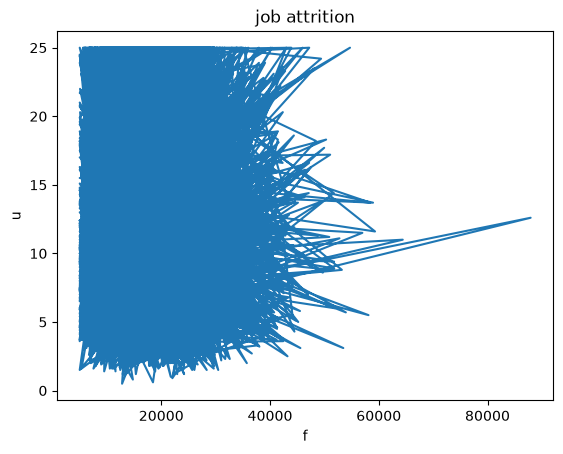

In [36]:
plt.plot(df['Monthly_Expenses'],df['Salary_Hike_Percentage'])
plt.xlabel('f')
plt.ylabel('u')
plt.title('job attrition')
plt.show()

# Data visualizaton

# univariate Analysis (Single Column Analysis)

kde kernal density destinator

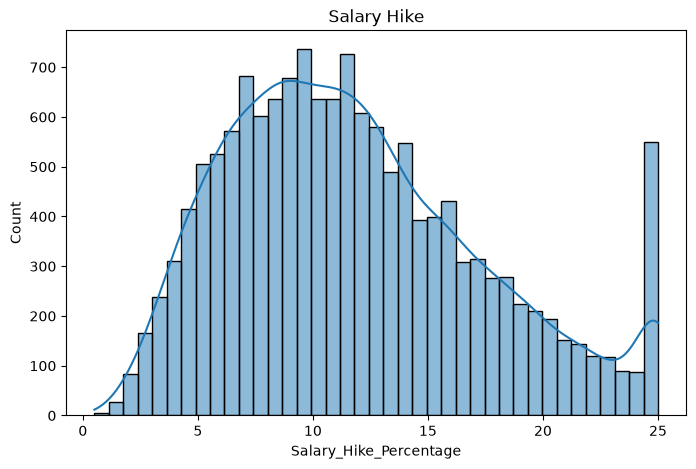

In [37]:
plt.figure(figsize=(8,5))
sns.histplot(df['Salary_Hike_Percentage'], kde=True)
plt.title("Salary Hike")
plt.show()

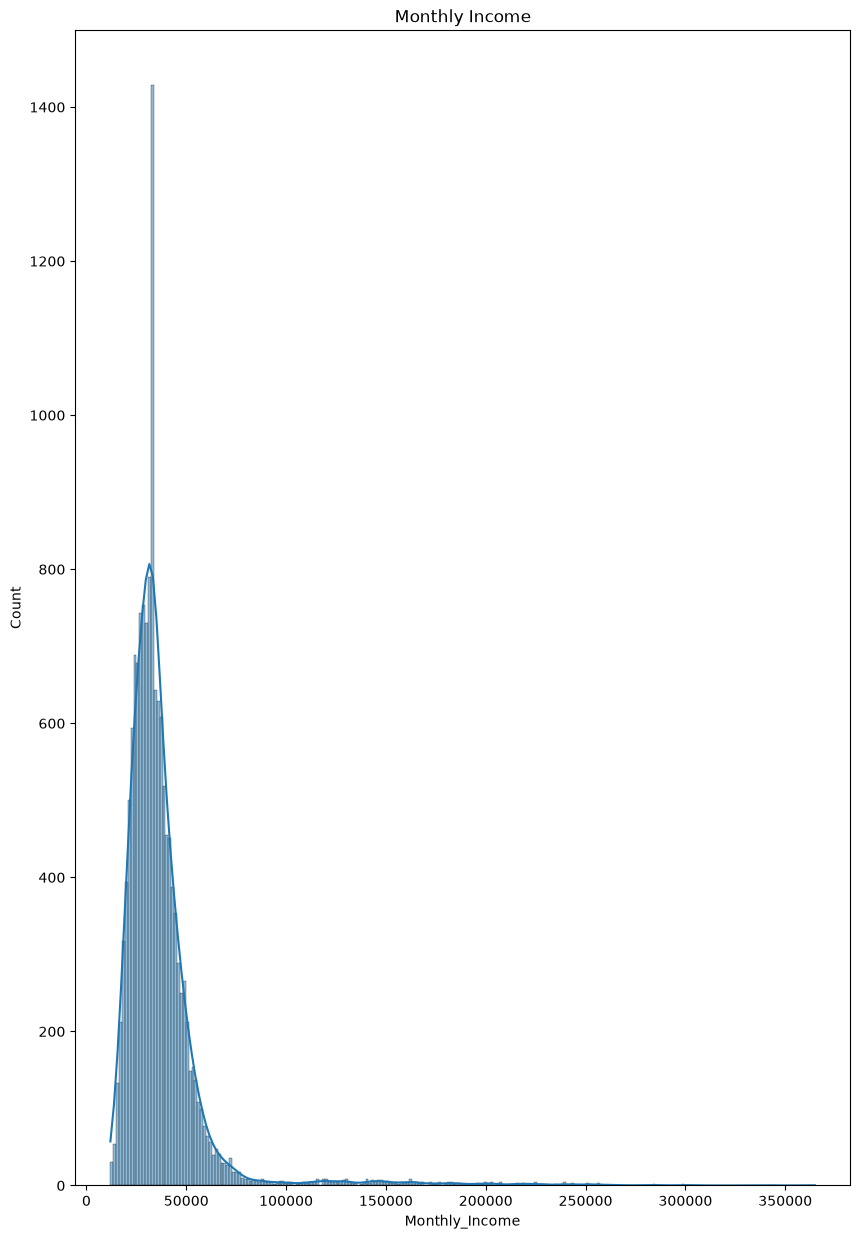

In [38]:
plt.figure(figsize=(10,15))
sns.histplot(df['Monthly_Income'], kde=True)
plt.title("Monthly Income")
plt.show()

In [39]:
df['Job_Satisfaction'].unique()


array([3., 1., 2., 4.])

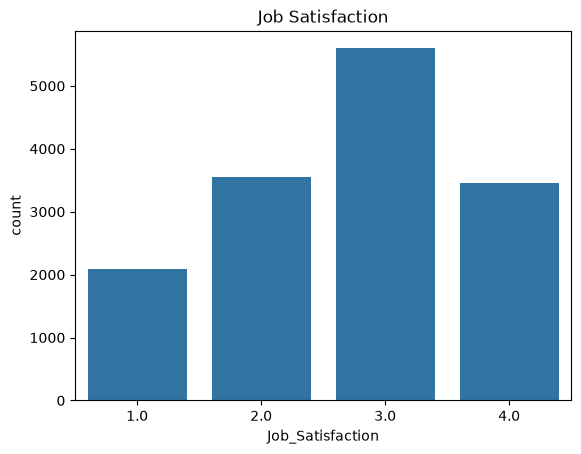

In [40]:
sns.countplot(x='Job_Satisfaction',data=df)
plt.title('Job Satisfaction')
plt.show()

In [41]:
a=df["Attrition"].value_counts()

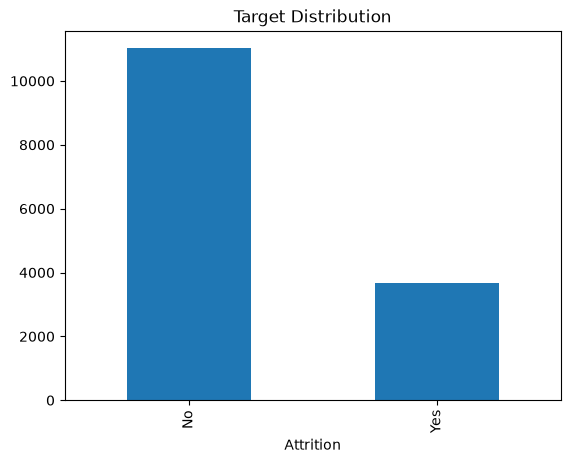

In [42]:
a.plot(kind='bar')
plt.title('Target Distribution')
plt.show()

Bivariate Analysis(2 variables)

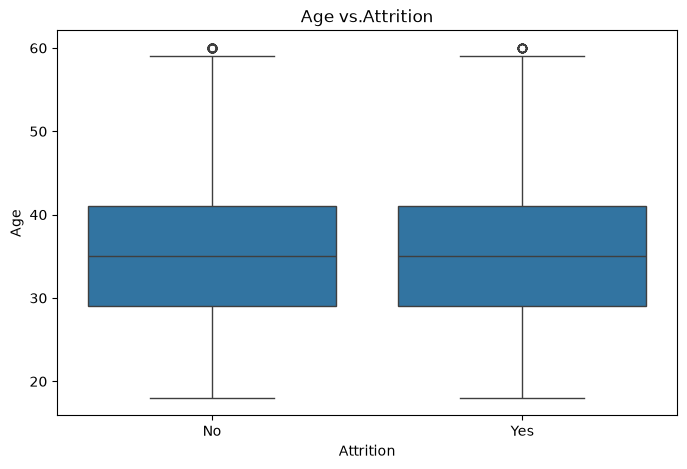

In [43]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Attrition',y='Age',data=df)
plt.title('Age vs.Attrition')
plt.show()

research the graph

(lowerbound,q1,median,q3,outlier)=Boxplot Graph

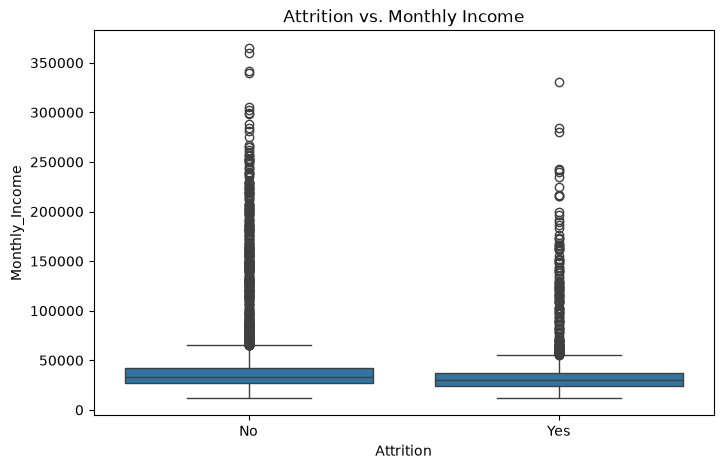

In [44]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Attrition',y='Monthly_Income',data=df)
plt.title('Attrition vs. Monthly Income')
plt.show()

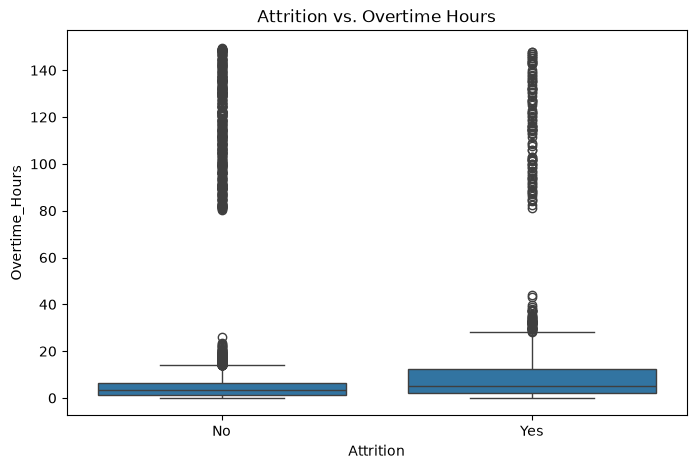

In [45]:
plt.figure(figsize=(8,5))
sns.boxplot(x='Attrition',y='Overtime_Hours',data=df)
plt.title('Attrition vs. Overtime Hours')
plt.show()

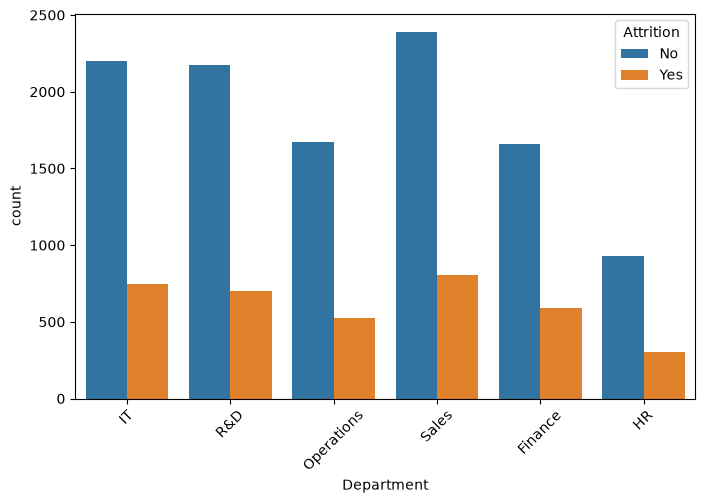

In [46]:
plt.figure(figsize=(8,5))
sns.countplot(x='Department',hue='Attrition',data=df)
plt.xticks(rotation=45)
plt.show()

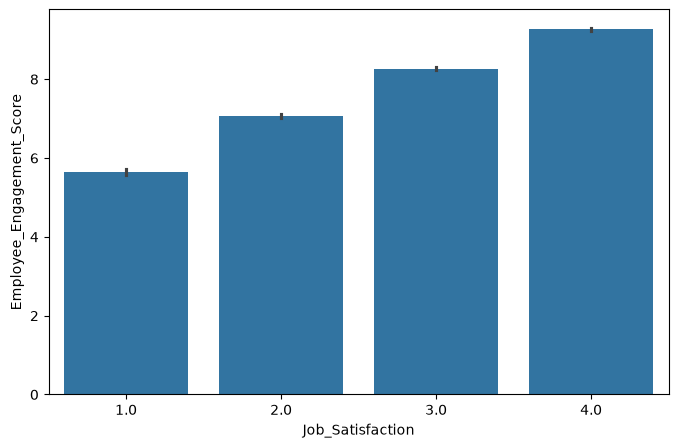

In [47]:
plt.figure(figsize=(8,5))
sns.barplot(x='Job_Satisfaction',y='Employee_Engagement_Score',data=df)
plt.show()

Multivariate Analysis(3 or more features)

KDE-Kernel Density Estimation (curve line drawn in a graph)

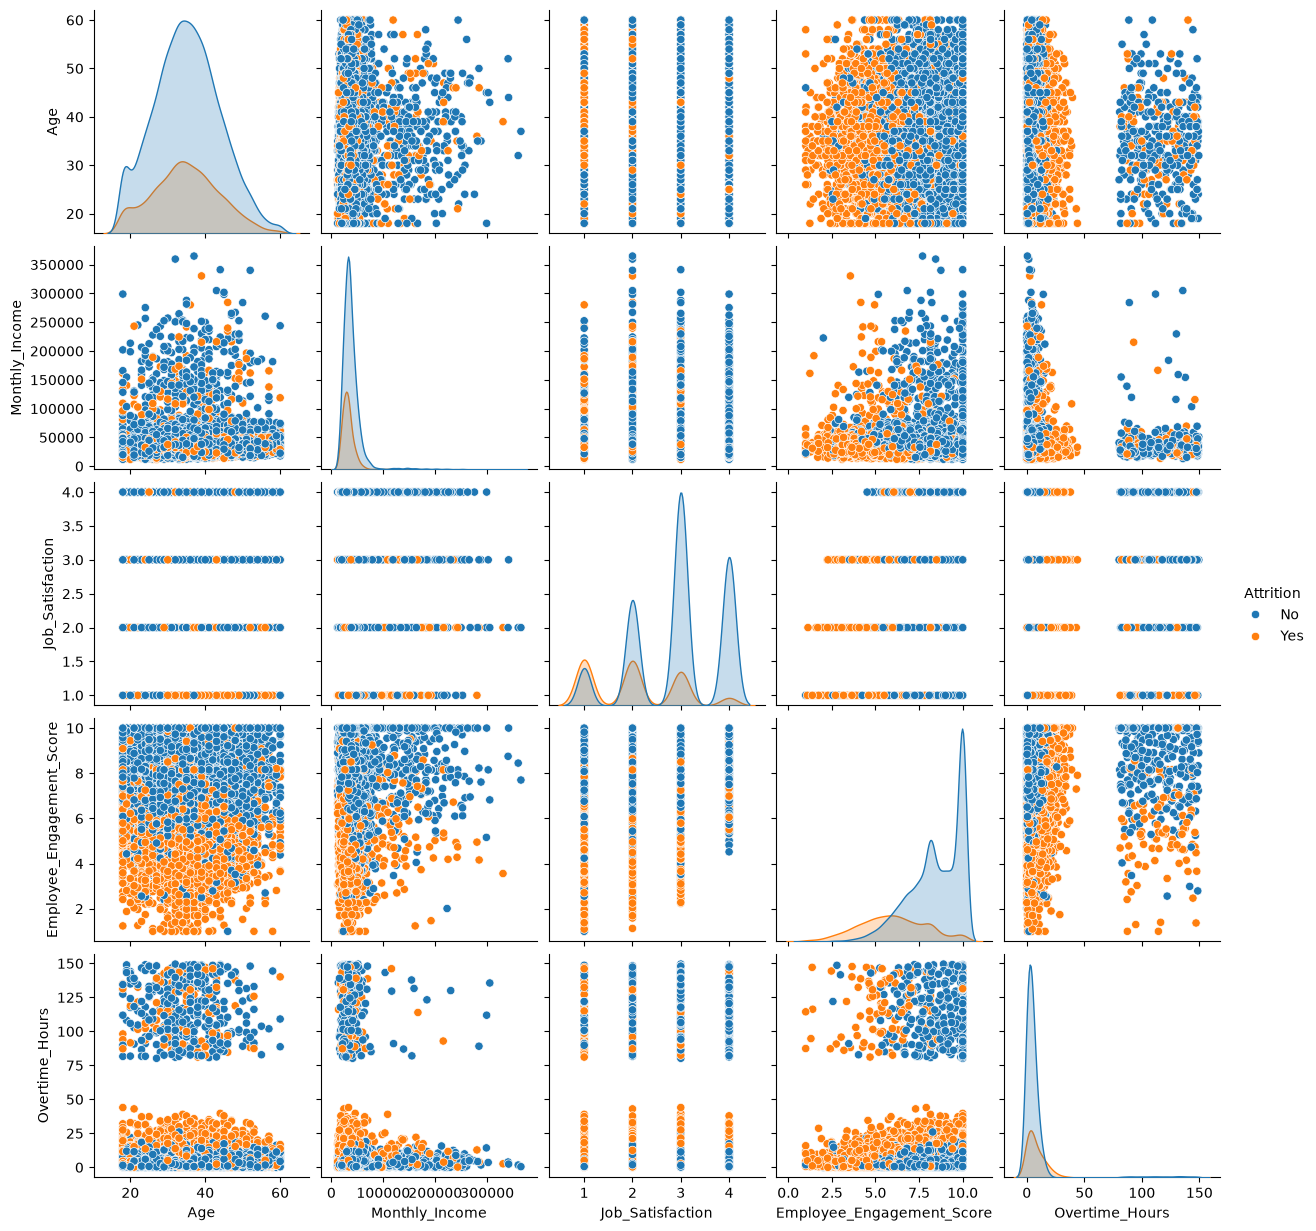

In [48]:
cols = ['Age','Monthly_Income','Job_Satisfaction','Employee_Engagement_Score','Overtime_Hours','Attrition']
sns.pairplot(df[cols],hue='Attrition')
plt.show()

## Outliers Handling

#Outliers for numbers

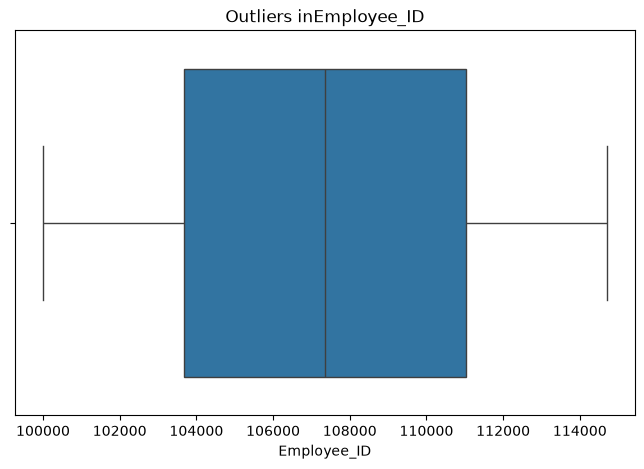

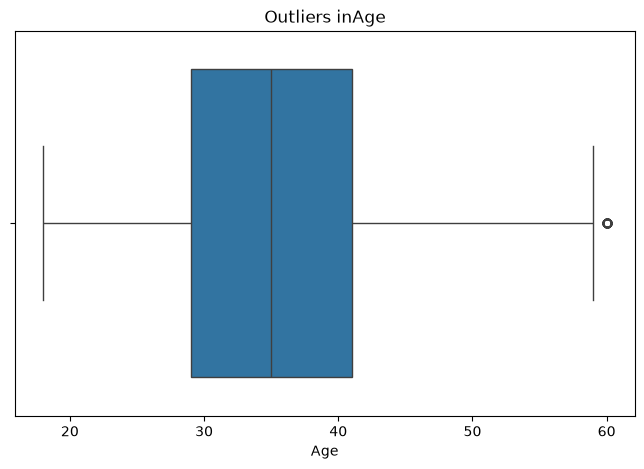

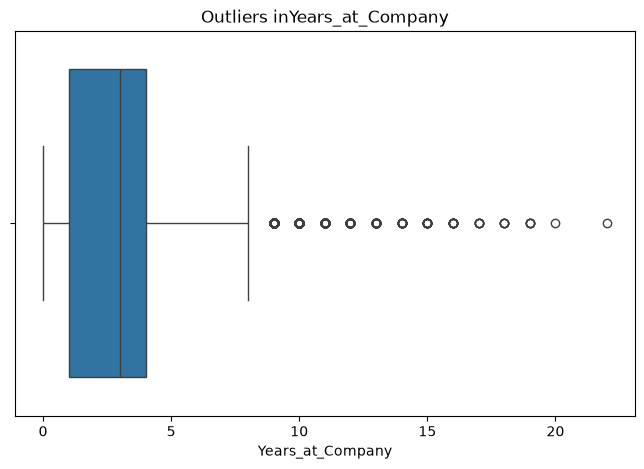

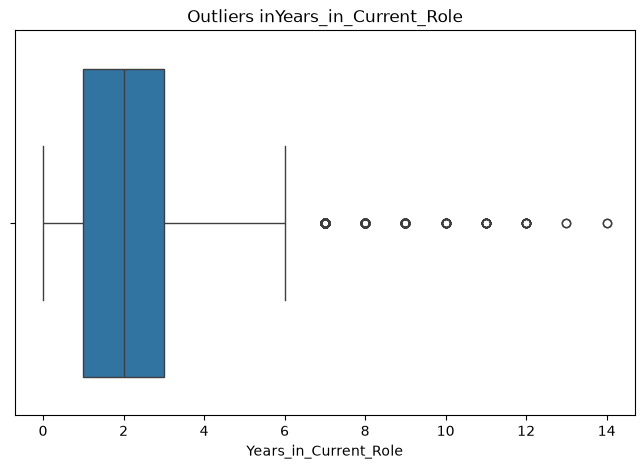

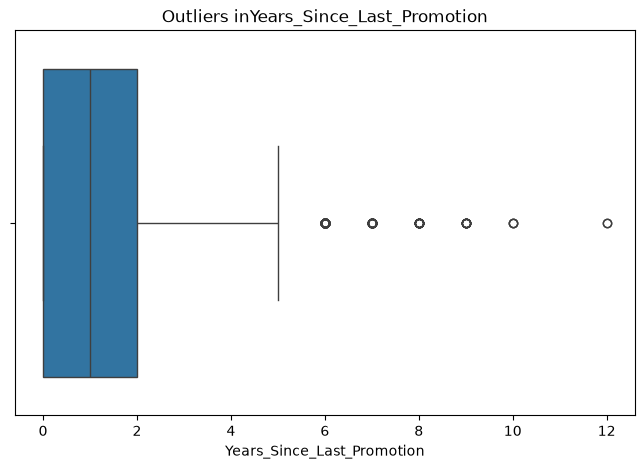

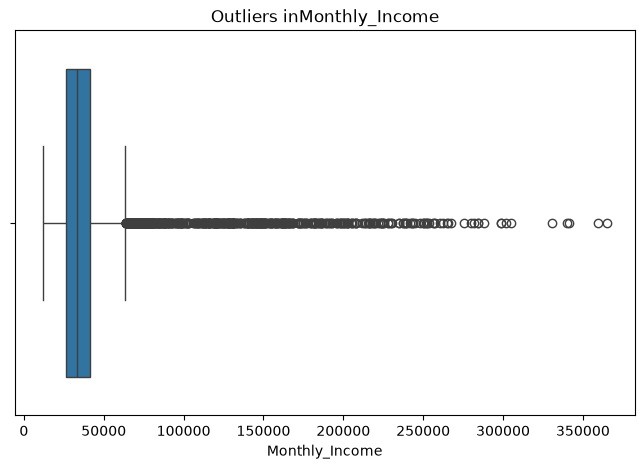

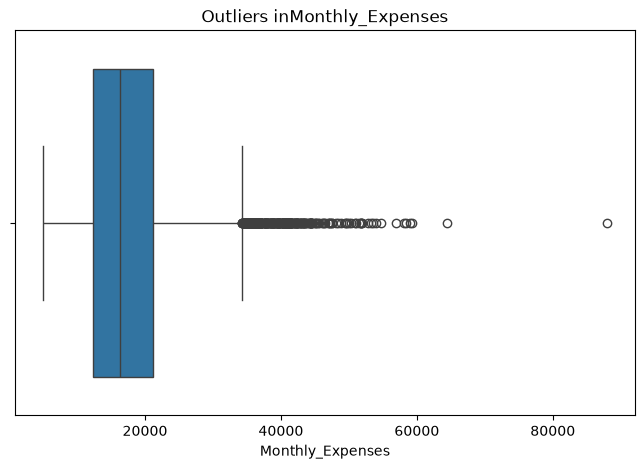

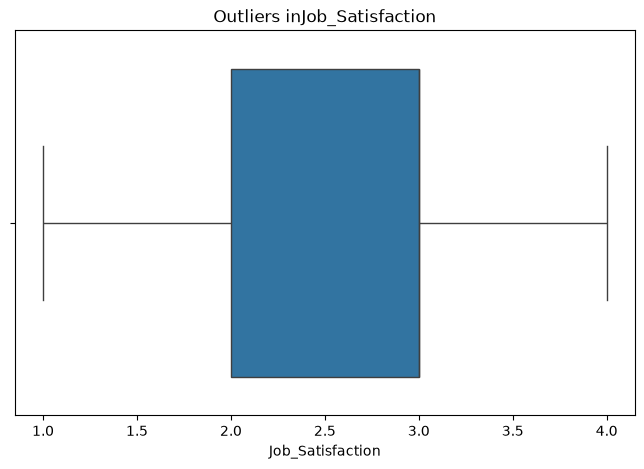

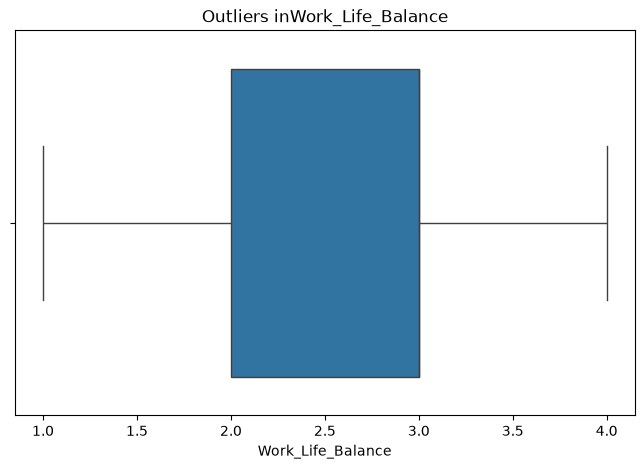

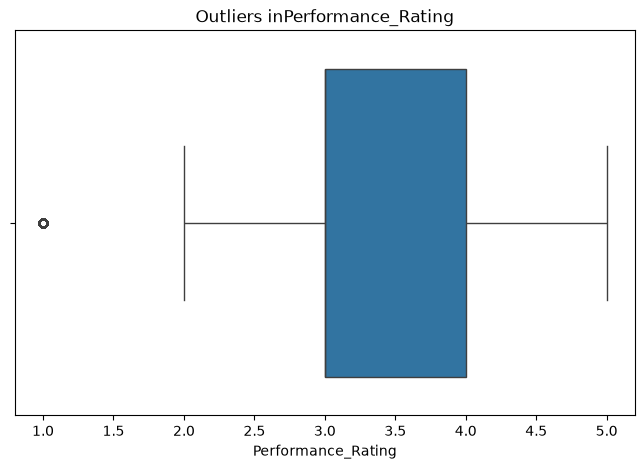

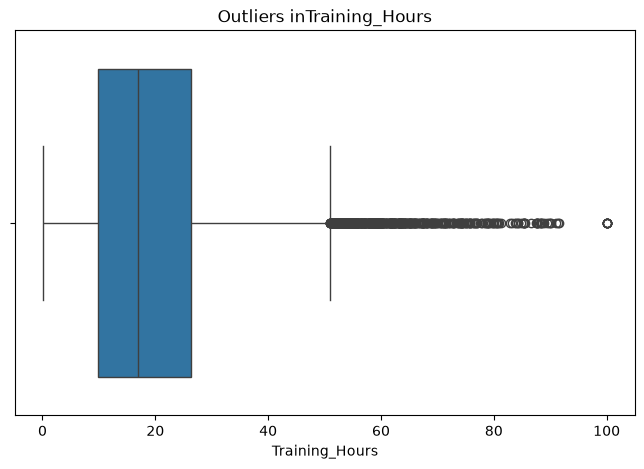

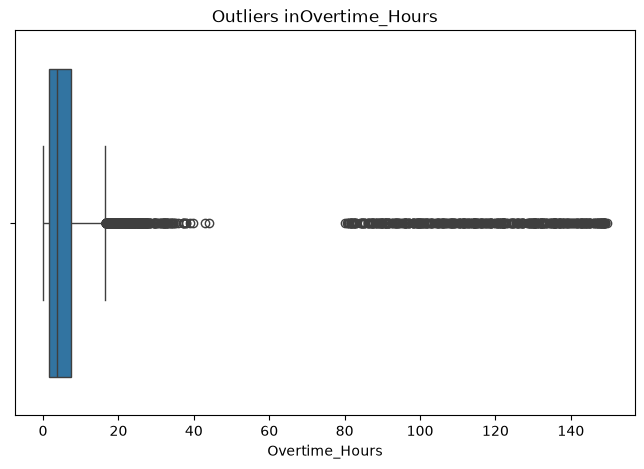

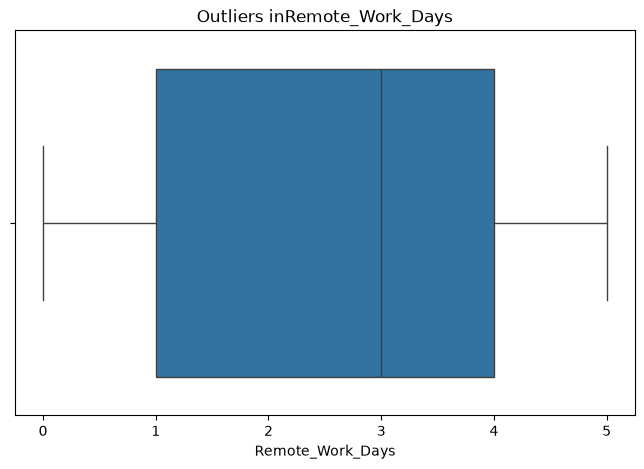

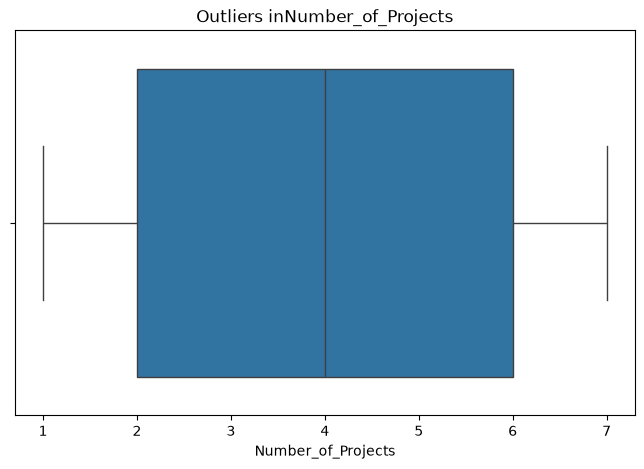

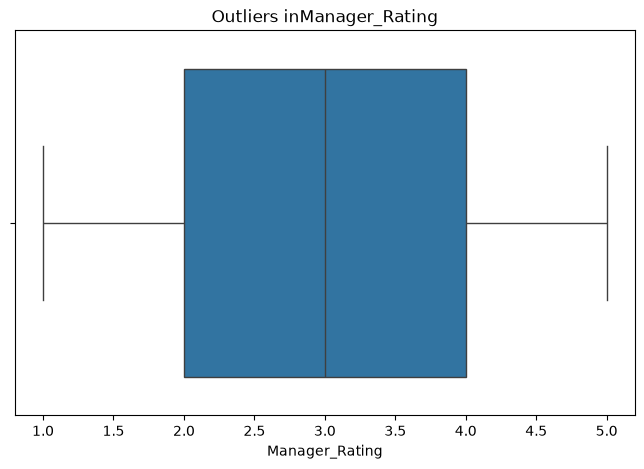

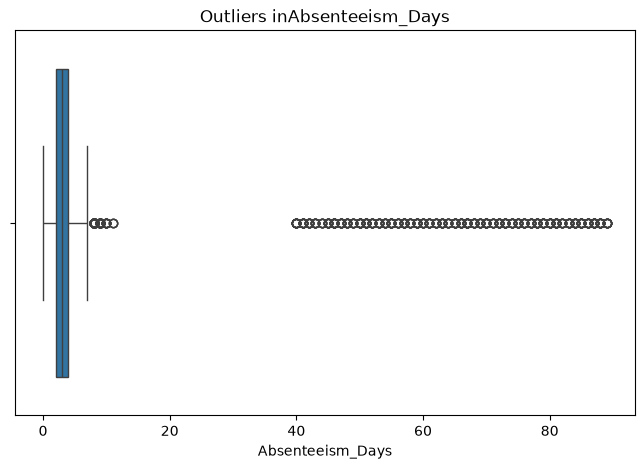

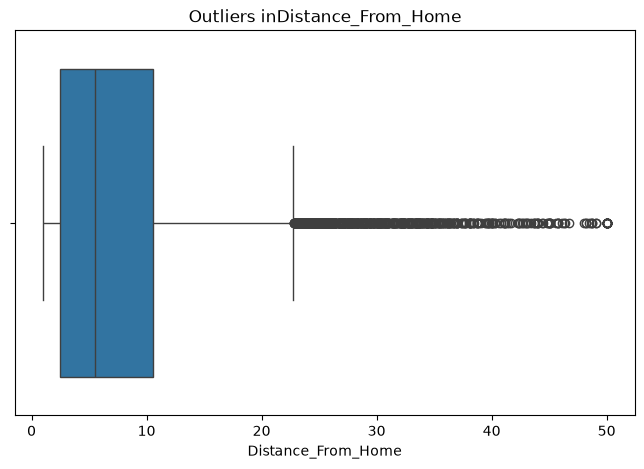

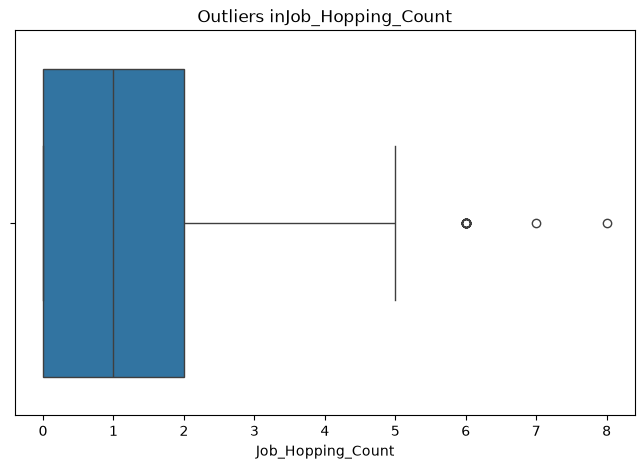

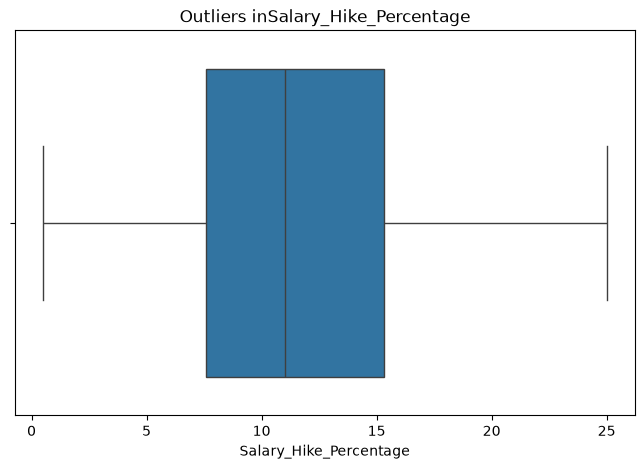

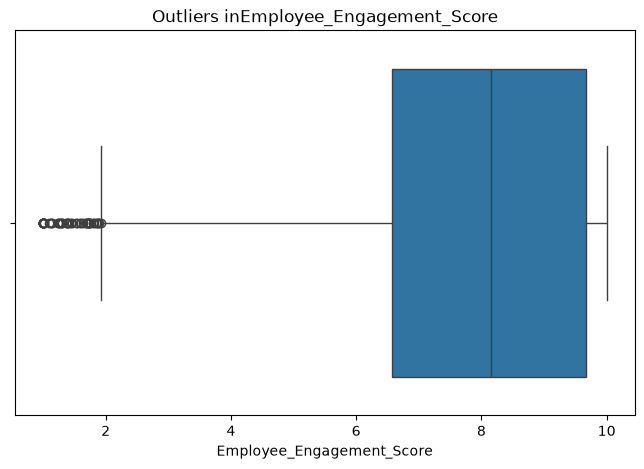

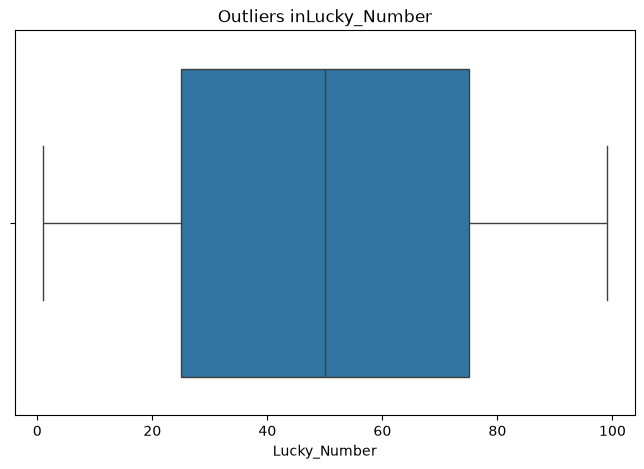

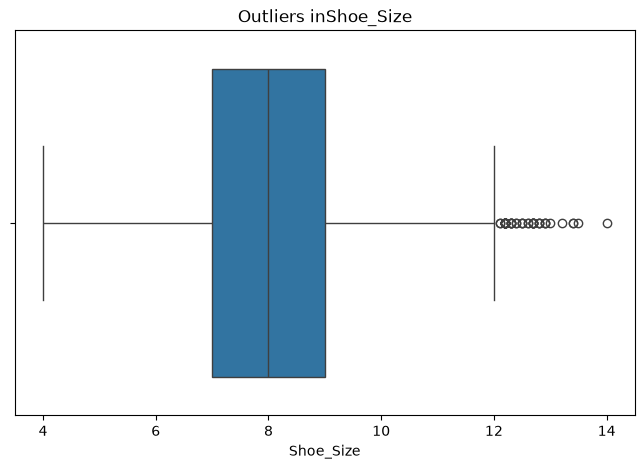

In [49]:
num_cols = df.select_dtypes(include='number').columns   
for col in num_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df[col])
    plt.title(f'Outliers in{col}')
    plt.show()

#Outliers for objects

In [50]:
# obj_cols = df.select_dtypes(include='object').columns   
# for col in obj_cols:
#     plt.figure(figsize=(8,5))
#     sns.boxplot(x=df[col])
#     plt.title(f'Outliers in{col}')
#     plt.show()

#Types of Handlings---IQR Method (Interquartile Range) =Median,Z-Score Method
                       

In [51]:
num_cols = df.select_dtypes(include='number').columns
for col in num_cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-(1.5*IQR)
    upper_bound=Q3+(1.5*IQR)
    df=df[(df[col]>=lower_bound) &
           (df[col]<=upper_bound)]
print("new shape:", df.shape)

new shape: (8330, 30)


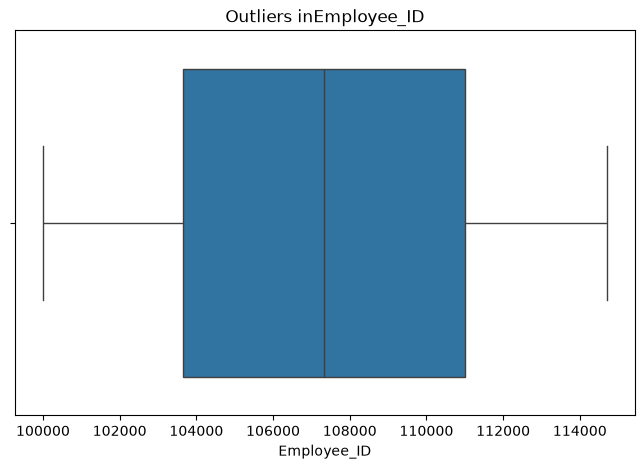

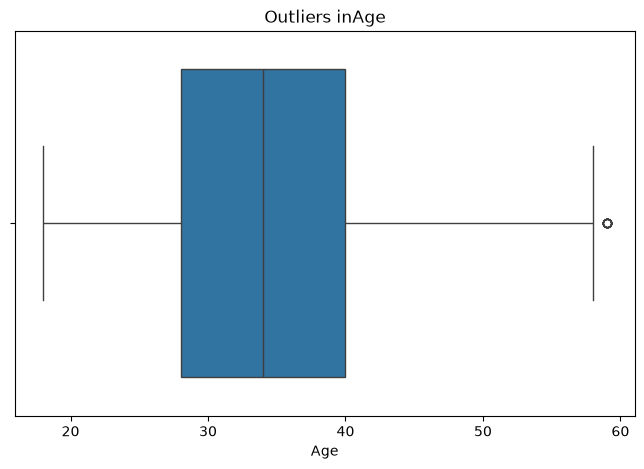

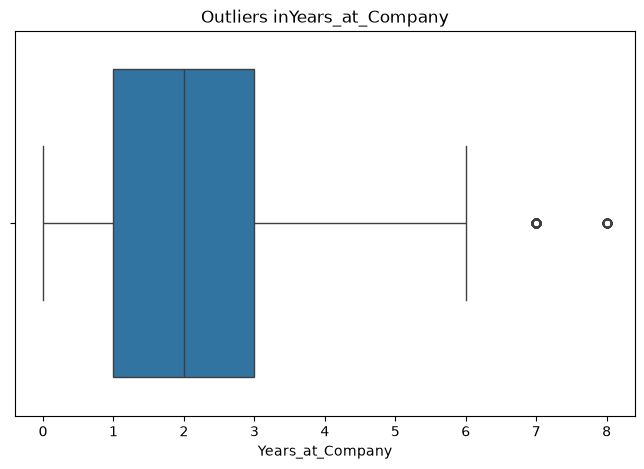

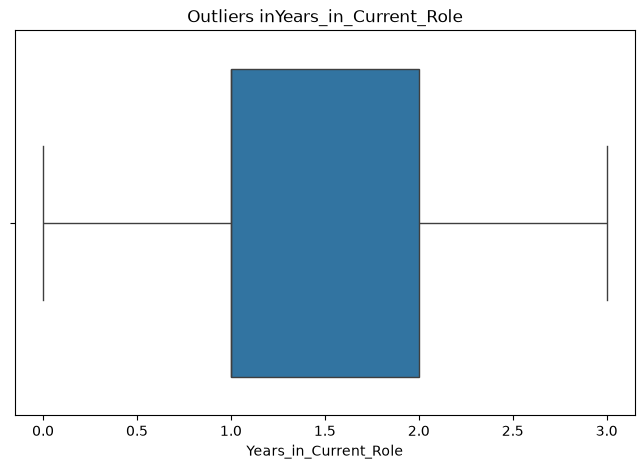

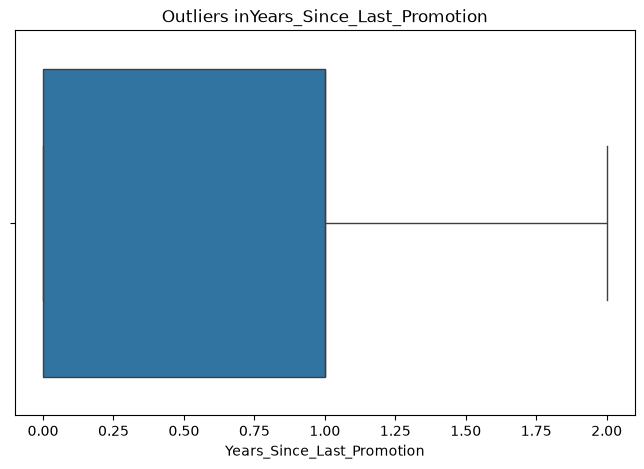

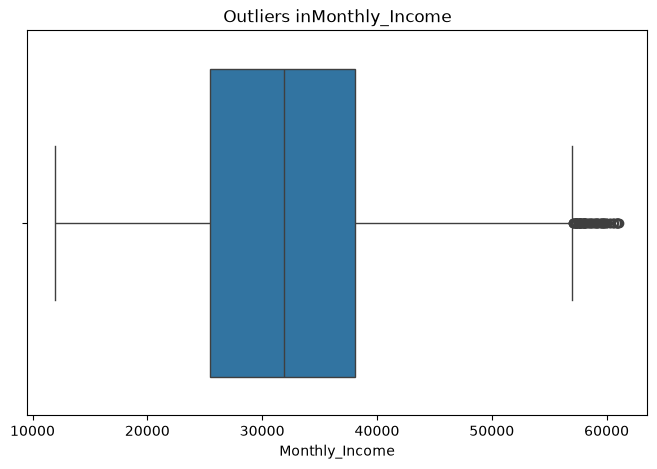

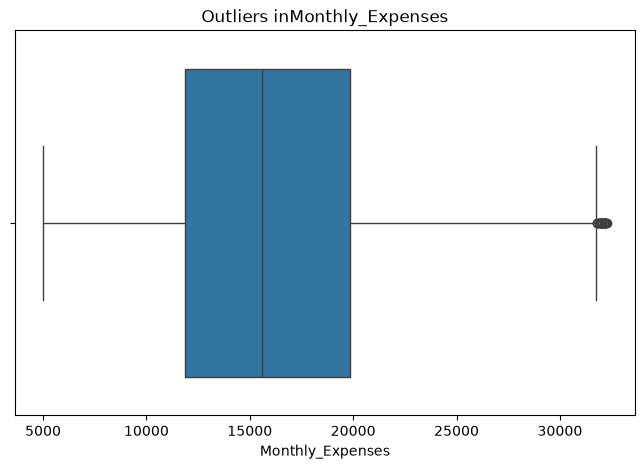

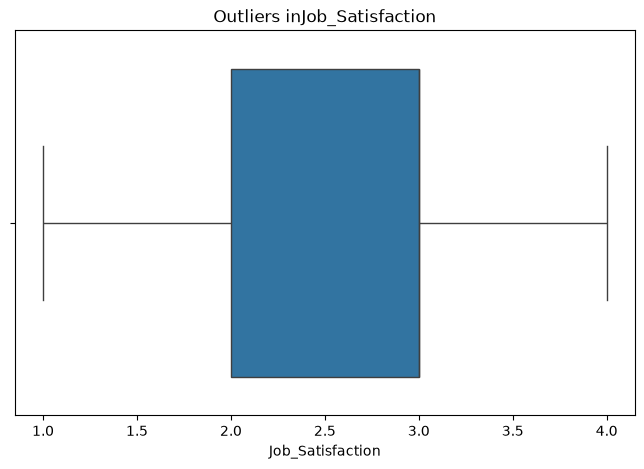

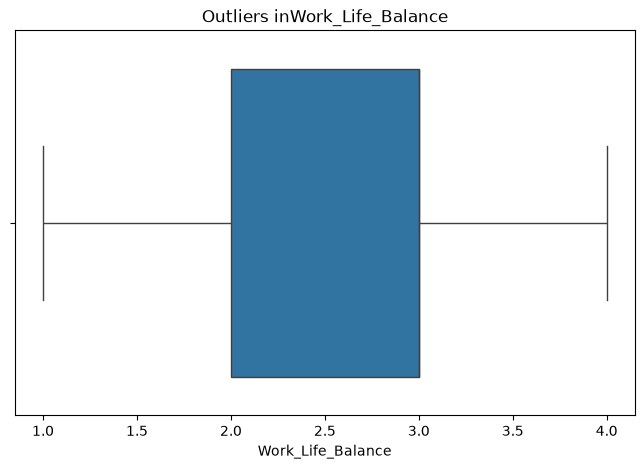

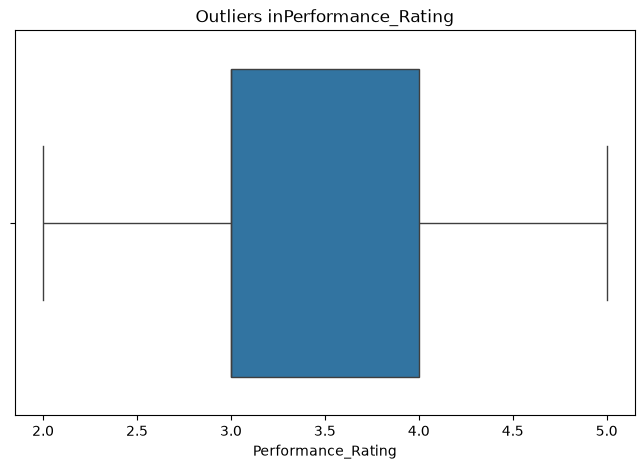

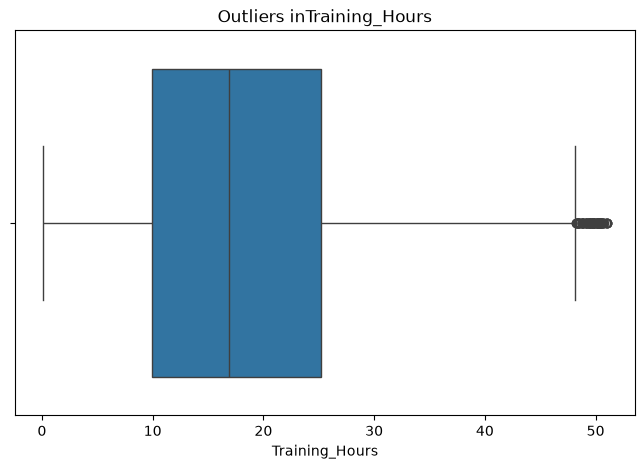

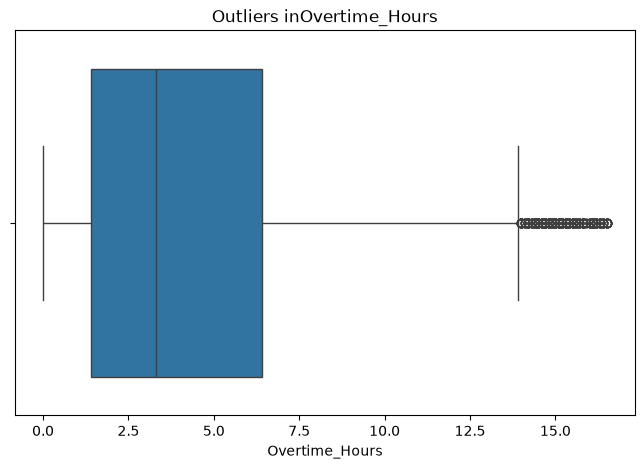

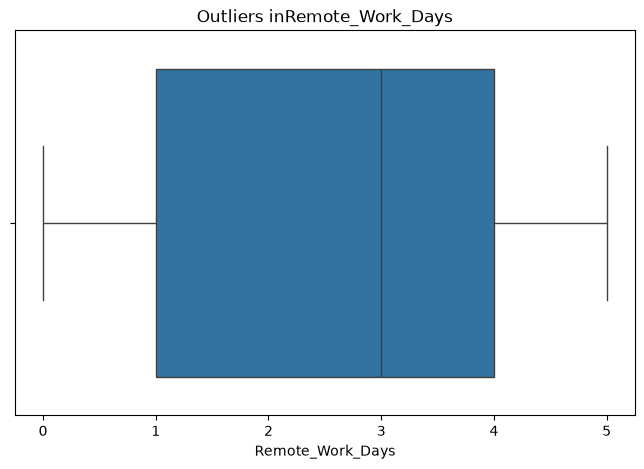

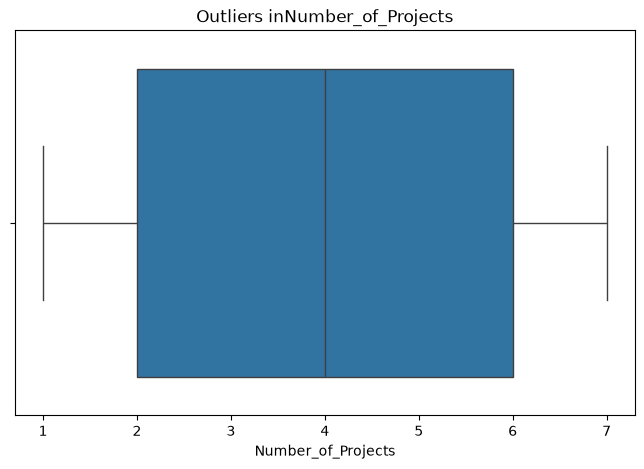

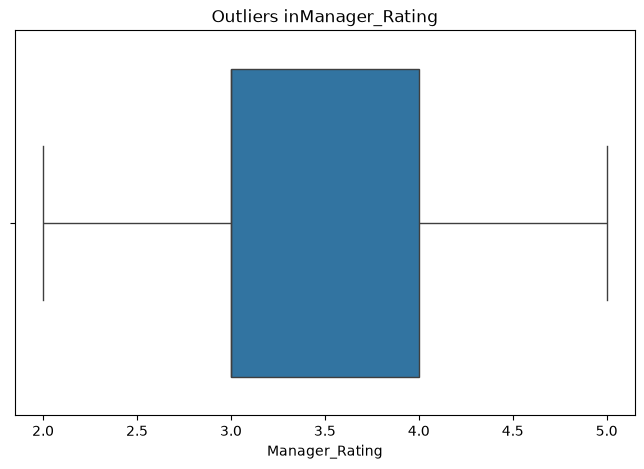

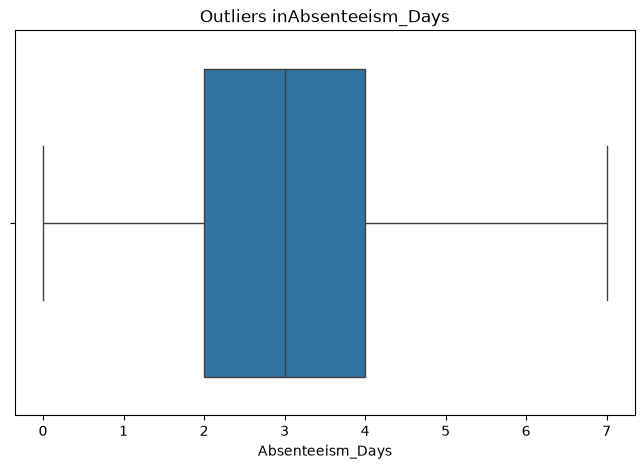

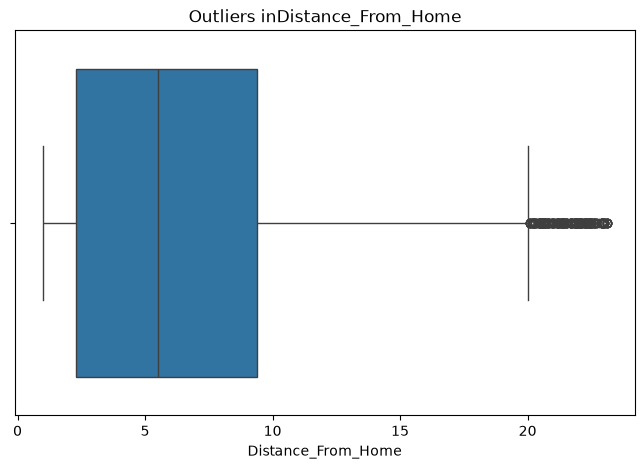

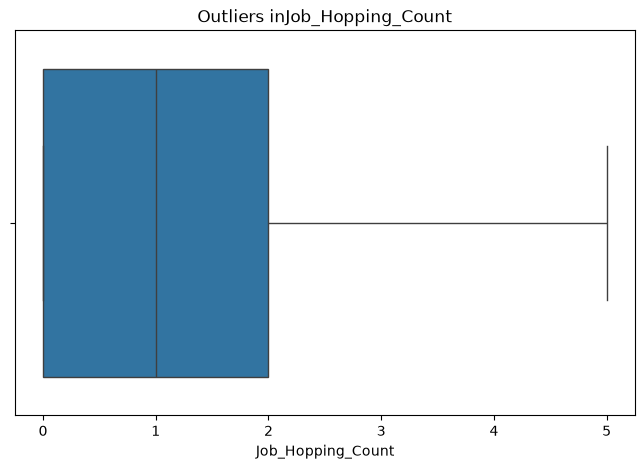

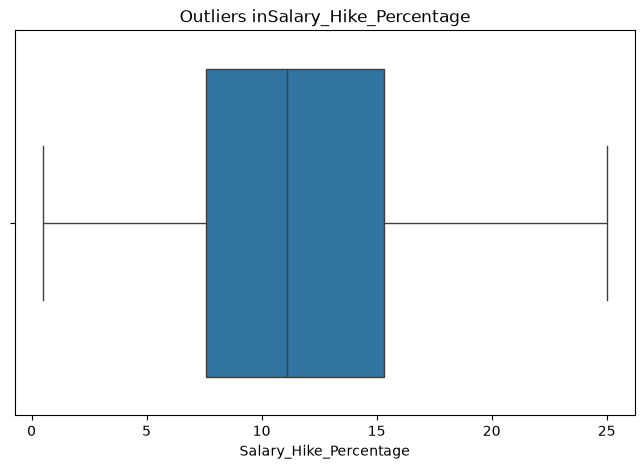

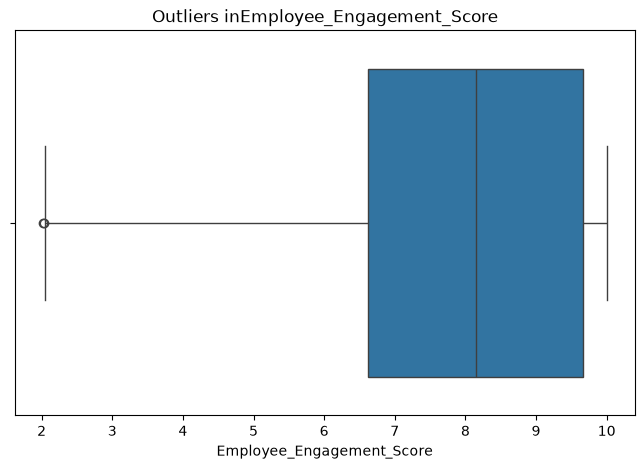

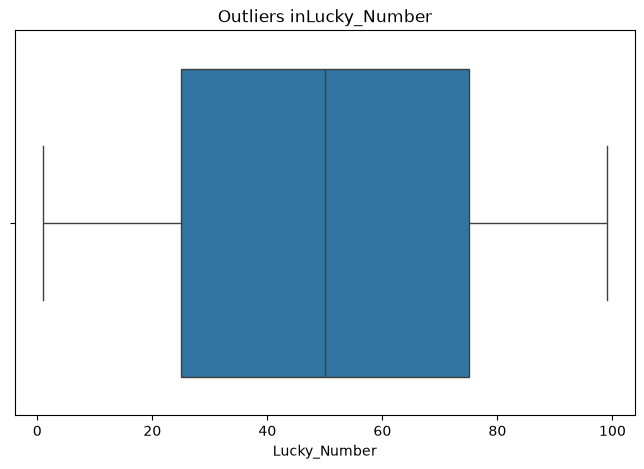

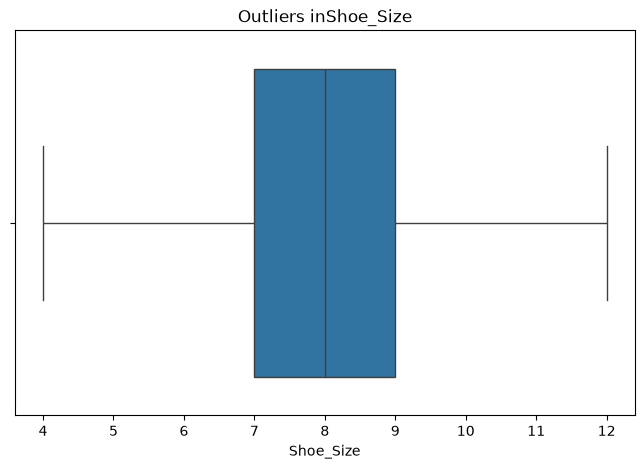

In [52]:
num_cols = df.select_dtypes(include='number').columns   
for col in num_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df[col])
    plt.title(f'Outliers in{col}')
    plt.show()

In [53]:
num_cols = df.select_dtypes(include='number').columns
for col in num_cols:
    Q1=df[col].quantile(0.25)
    Q3=df[col].quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-(1*IQR)
    upper_bound=Q3+(1*IQR)
    df=df[(df[col]>=lower_bound) &
           (df[col]<=upper_bound)]
print("new shape:", df.shape)

new shape: (5115, 30)


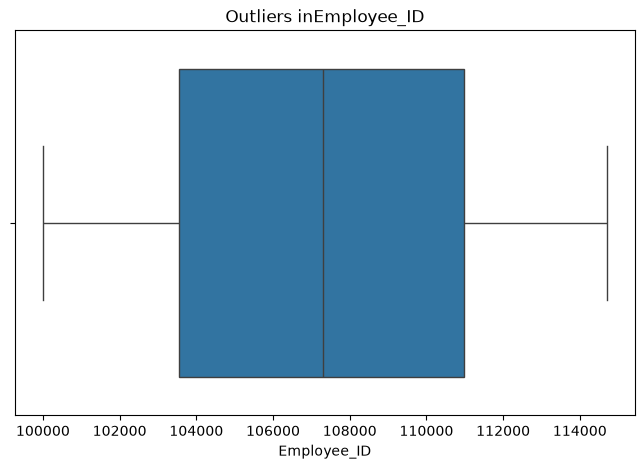

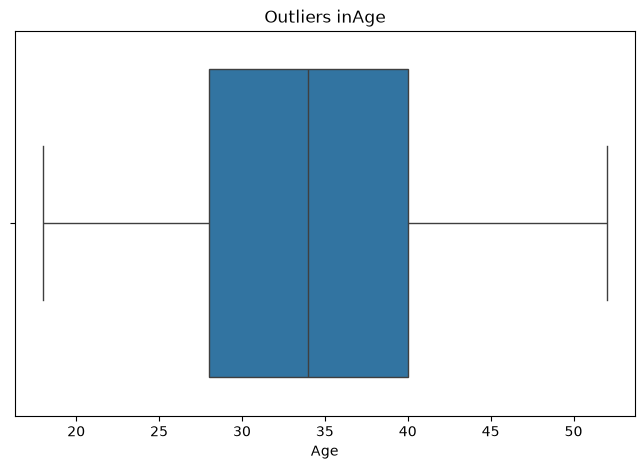

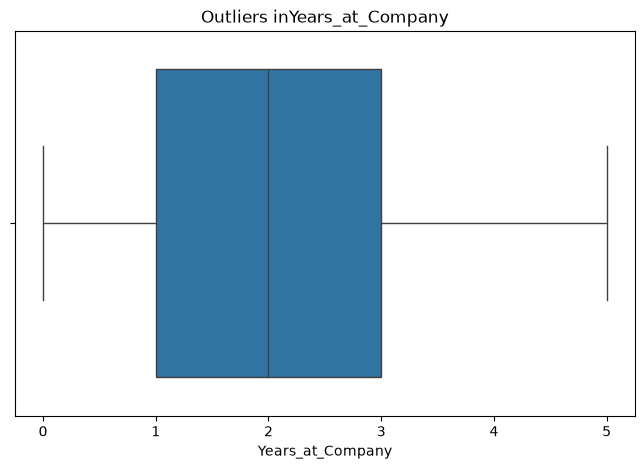

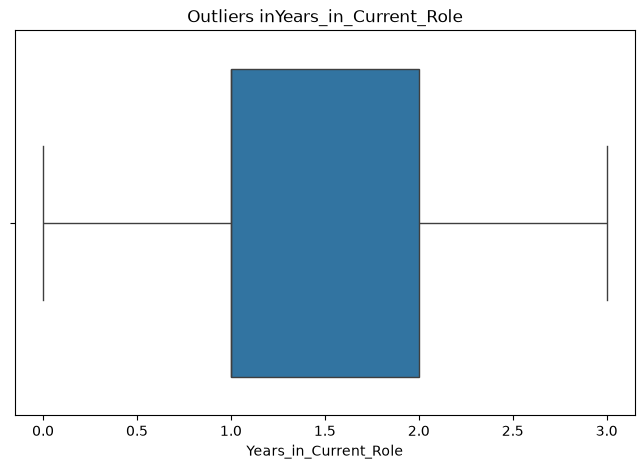

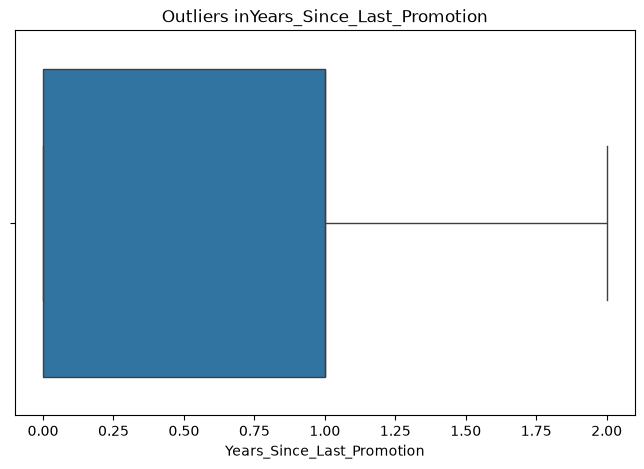

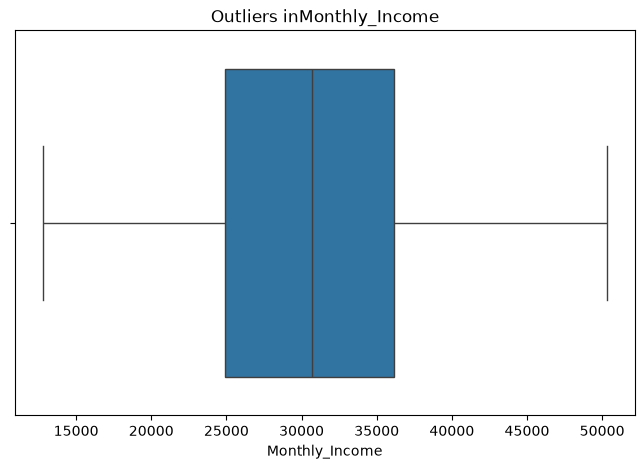

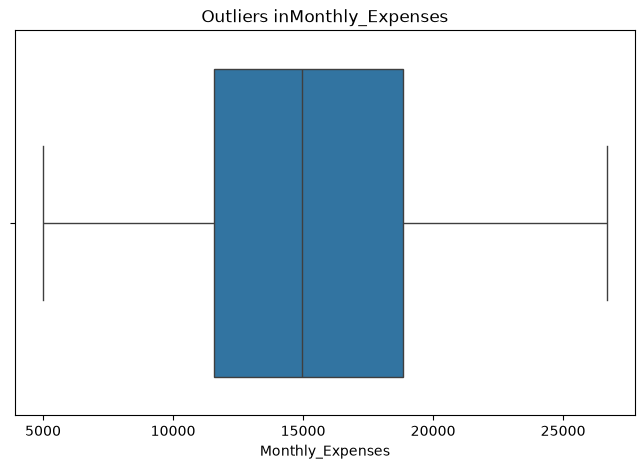

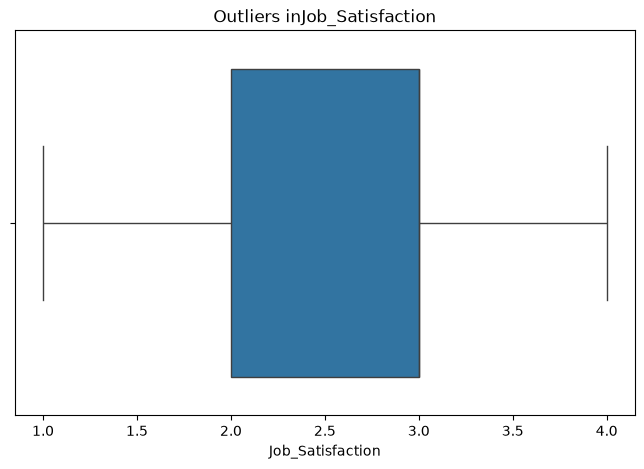

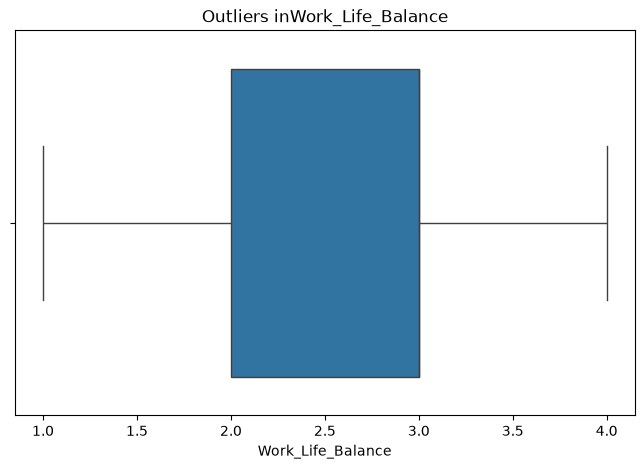

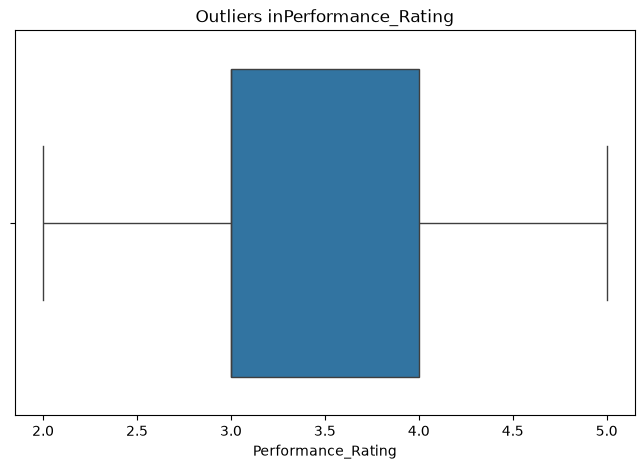

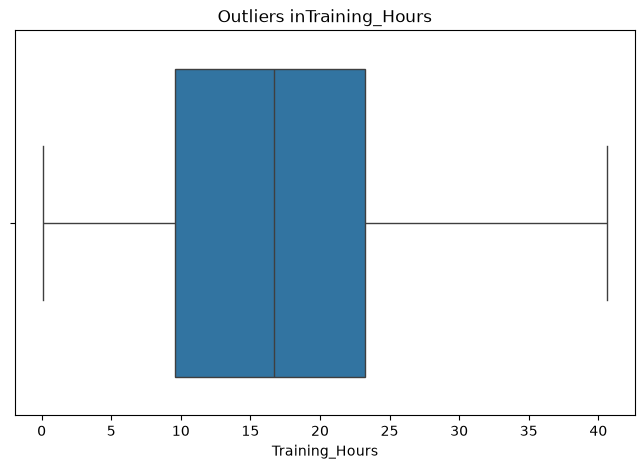

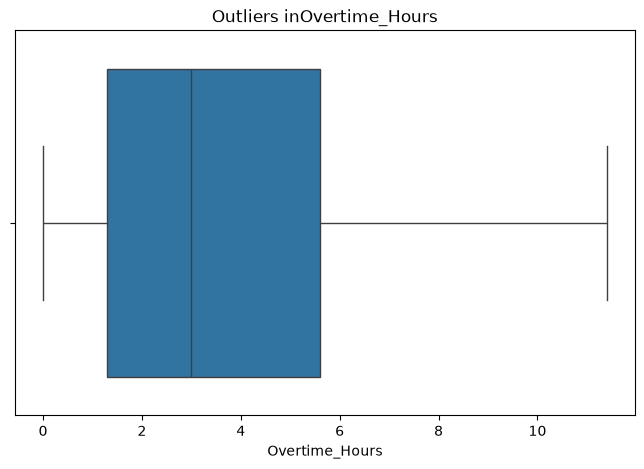

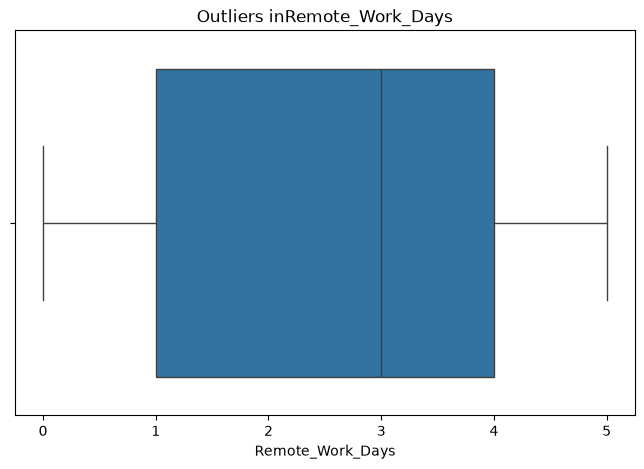

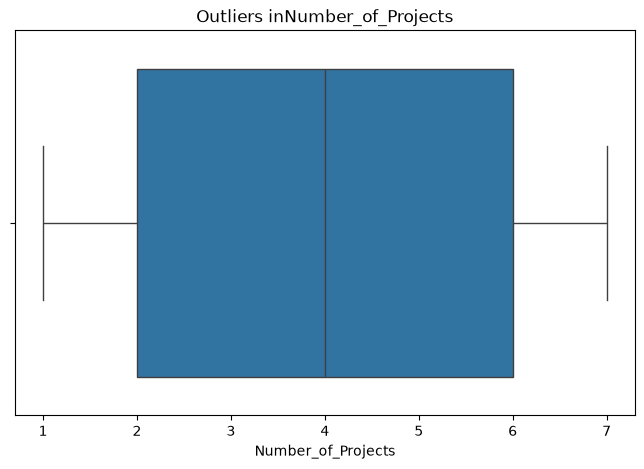

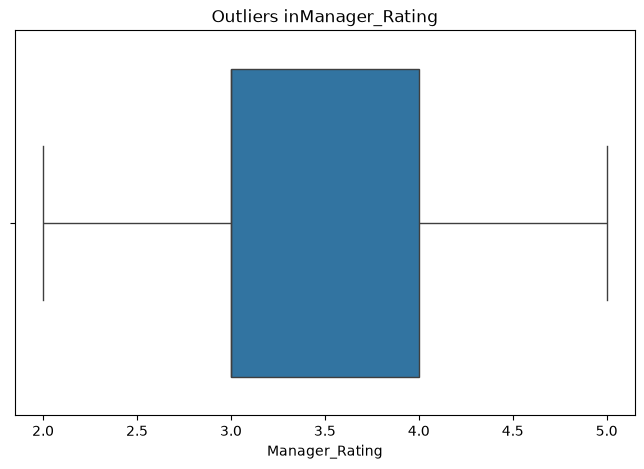

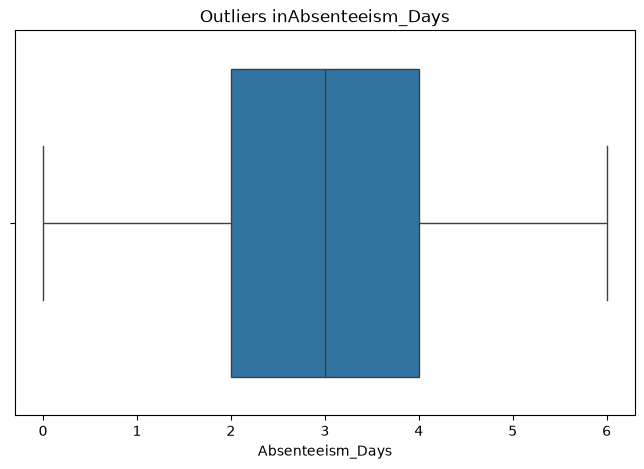

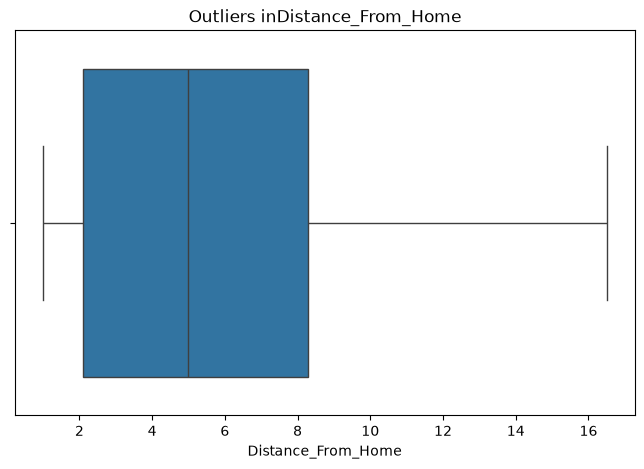

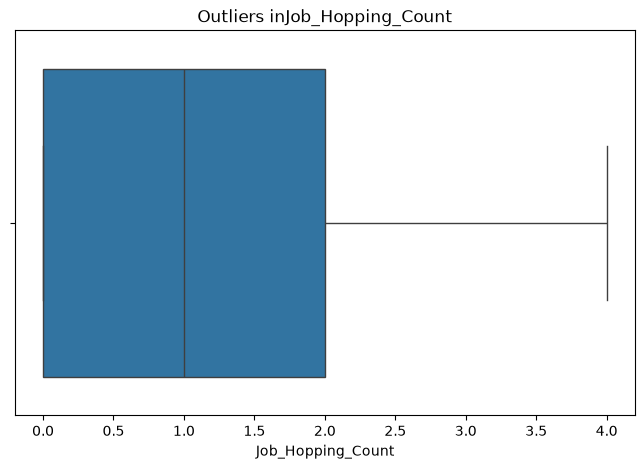

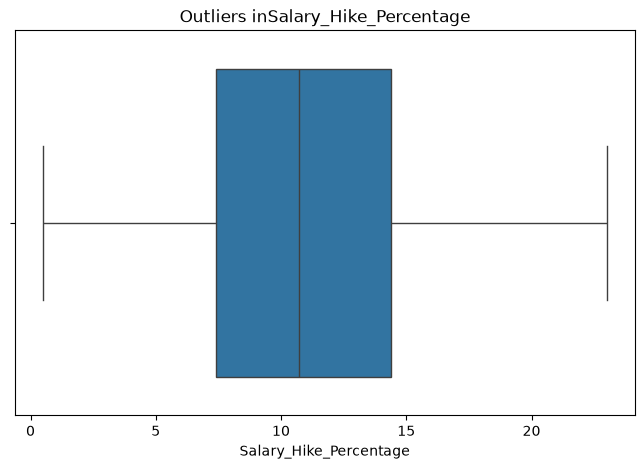

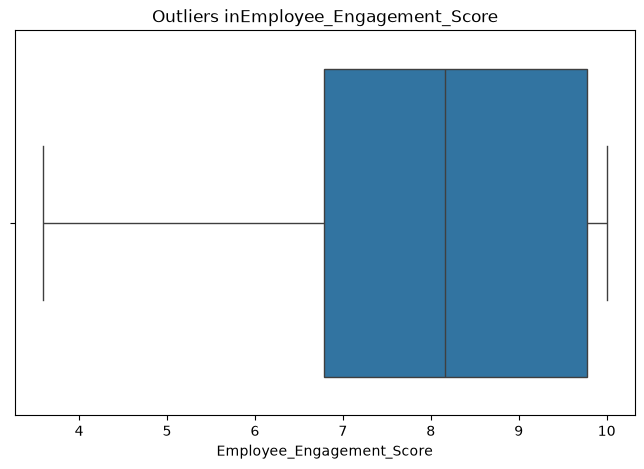

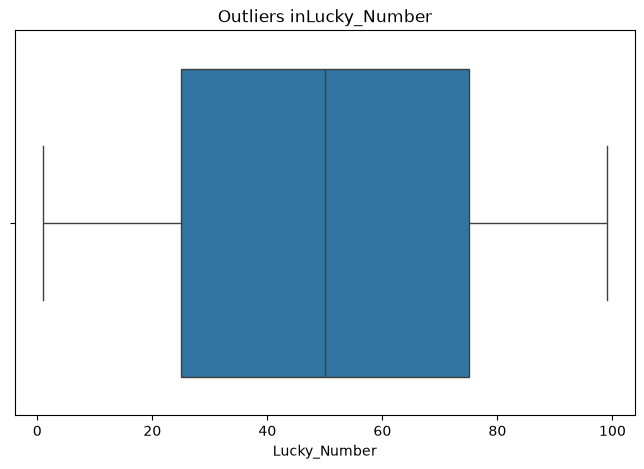

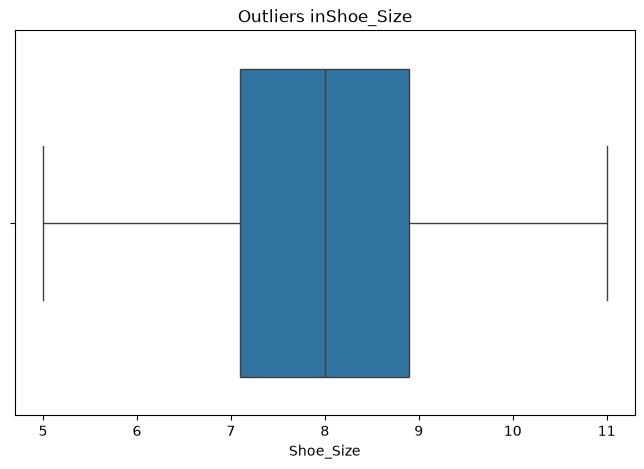

In [54]:
num_cols = df.select_dtypes(include='number').columns   
for col in num_cols:
    plt.figure(figsize=(8,5))
    sns.boxplot(x=df[col])
    plt.title(f'Outliers in{col}')
    plt.show()

# Feature Engineering

In [55]:
df['Savings_Ratio']=df['Monthly_Income']/(df['Monthly_Expenses'])
df['Savings_Ratio']

0        1.721669
3        2.063019
10       2.228332
12       1.902554
13       1.789419
           ...   
14981    1.686287
14982    1.767309
14986    2.022514
14988    1.926867
14993    2.707923
Name: Savings_Ratio, Length: 5115, dtype: float64

In [56]:
df['Work_Stress_Score']=(df['Overtime_Hours']+df['Number_of_Projects']+df['Absenteeism_Days'])
df['Work_Stress_Score']

0         9.5
3        11.0
10       14.4
12        8.4
13        6.0
         ... 
14981     4.7
14982    11.7
14986    12.6
14988     7.3
14993     8.6
Name: Work_Stress_Score, Length: 5115, dtype: float64

In [57]:
df['Promotion_Gap']=(df['Years_at_Company']-df['Years_Since_Last_Promotion'])
df['Promotion_Gap']

0        1
3        0
10       2
12       1
13       0
        ..
14981    2
14982    2
14986    0
14988    1
14993    0
Name: Promotion_Gap, Length: 5115, dtype: int64

# Skweness Handling

In [58]:
num_cols=df.select_dtypes(include=['number']).columns
skew_values=df[num_cols].skew()
print(skew_values.sort_values(ascending=False))

Savings_Ratio                 1.724608
Distance_From_Home            0.788629
Overtime_Hours                0.772988
Job_Hopping_Count             0.690987
Promotion_Gap                 0.526959
Training_Hours                0.466135
Work_Stress_Score             0.354739
Salary_Hike_Percentage        0.343004
Years_Since_Last_Promotion    0.318480
Years_at_Company              0.284935
Years_in_Current_Role         0.284583
Monthly_Income                0.239488
Monthly_Expenses              0.187413
Absenteeism_Days              0.177452
Manager_Rating                0.132075
Performance_Rating            0.120473
Employee_ID                   0.024070
Lucky_Number                 -0.009267
Remote_Work_Days             -0.010526
Age                          -0.011621
Number_of_Projects           -0.011636
Shoe_Size                    -0.012726
Work_Life_Balance            -0.253024
Job_Satisfaction             -0.336246
Employee_Engagement_Score    -0.569038
dtype: float64


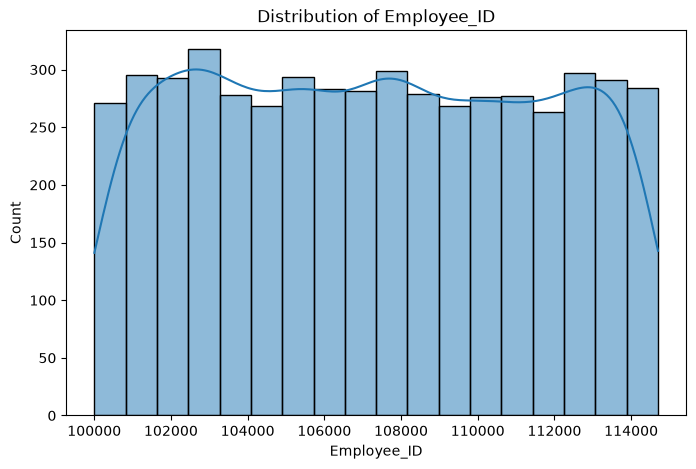

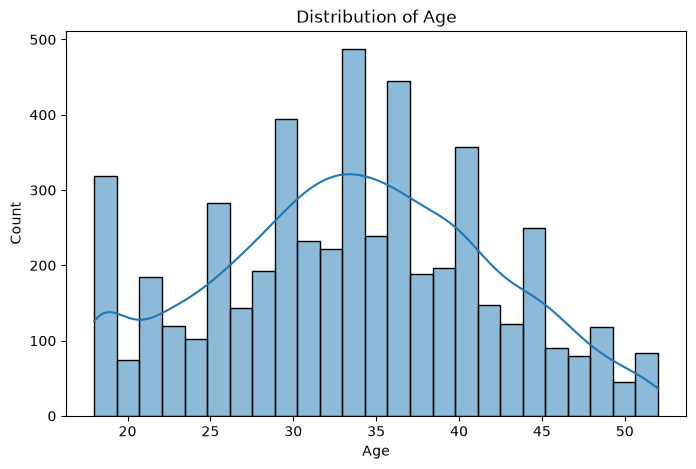

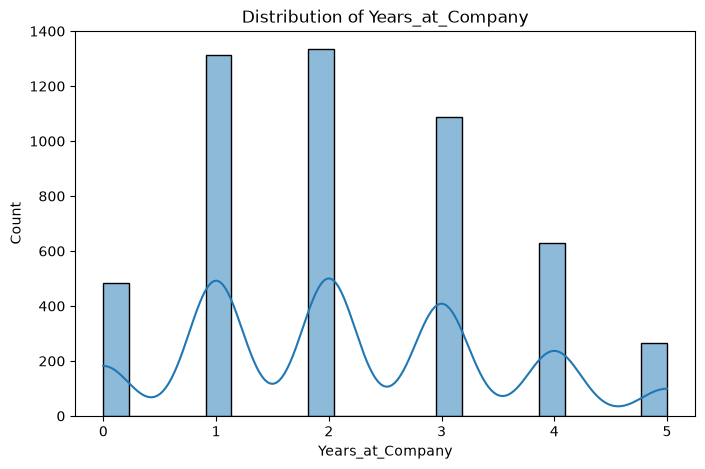

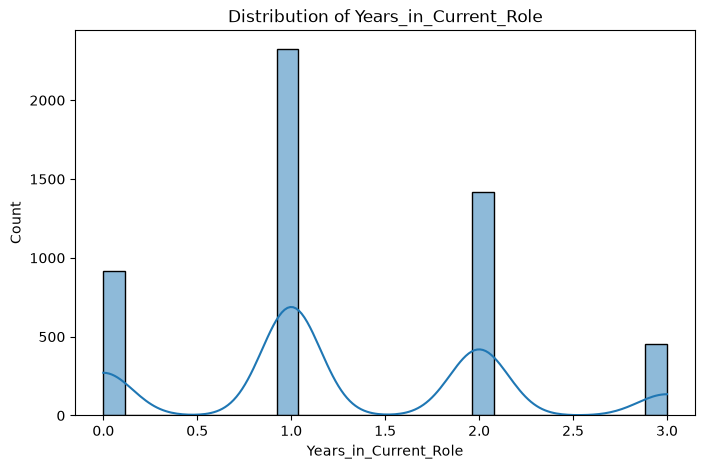

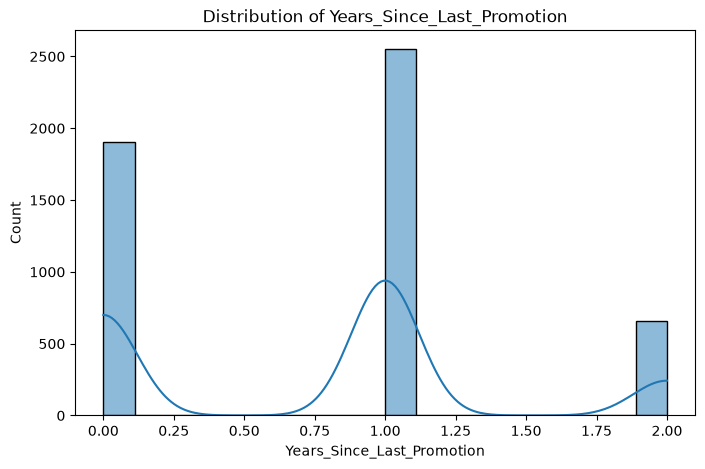

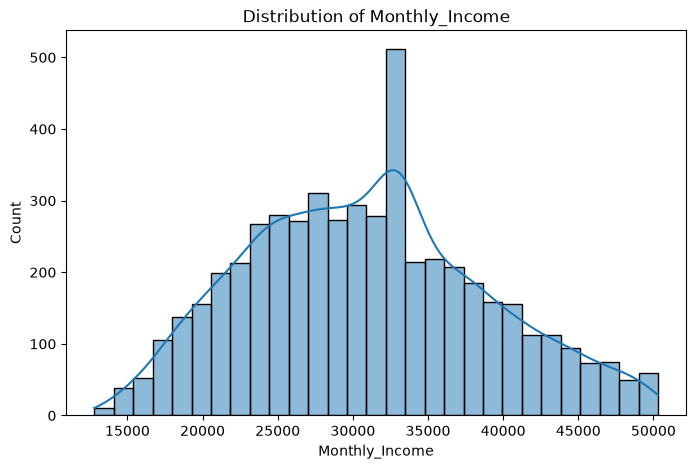

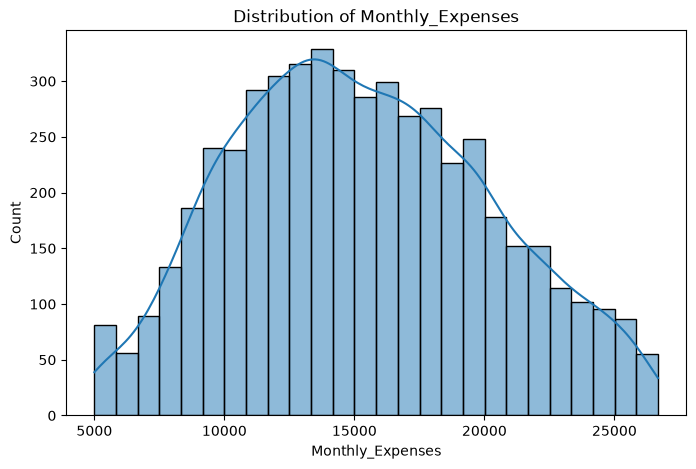

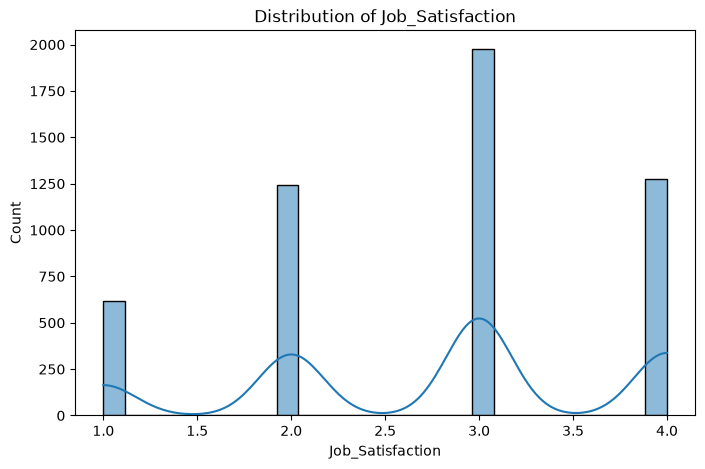

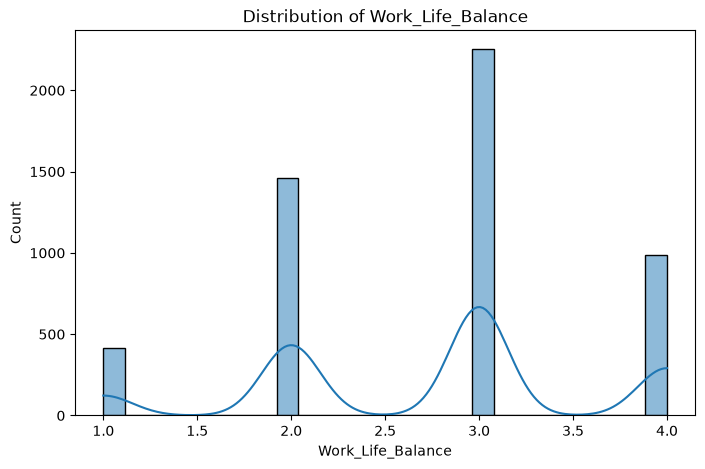

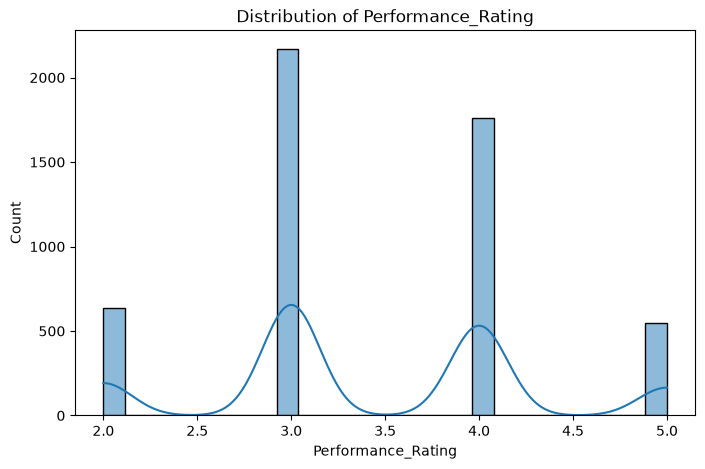

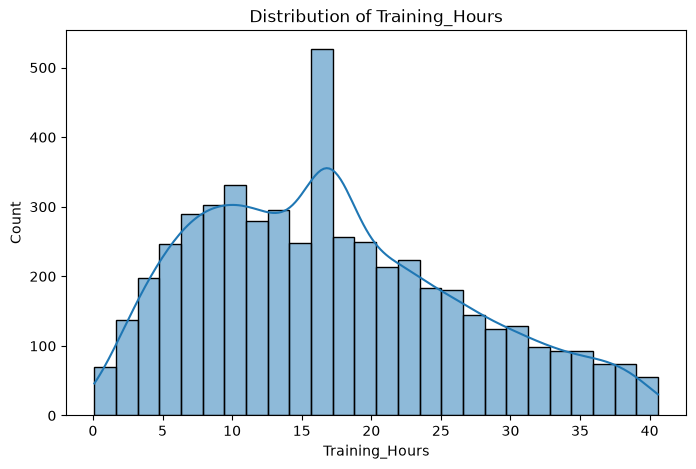

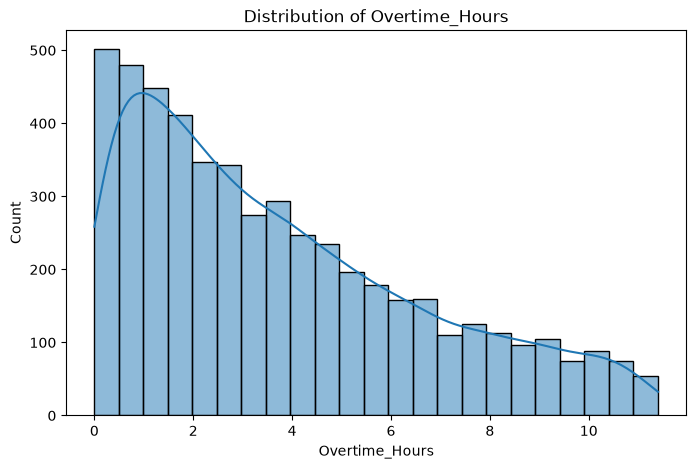

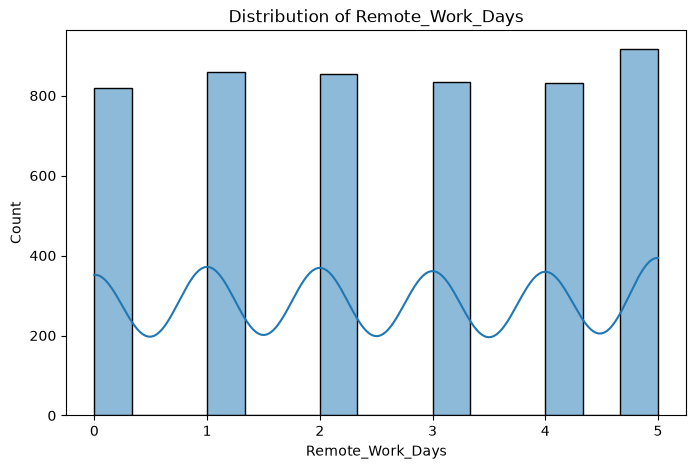

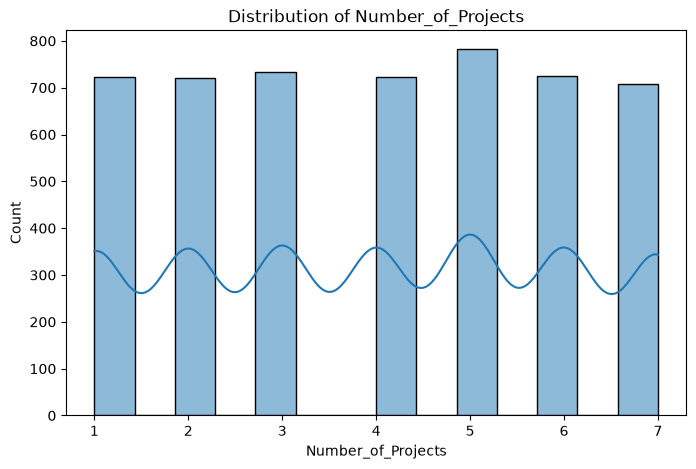

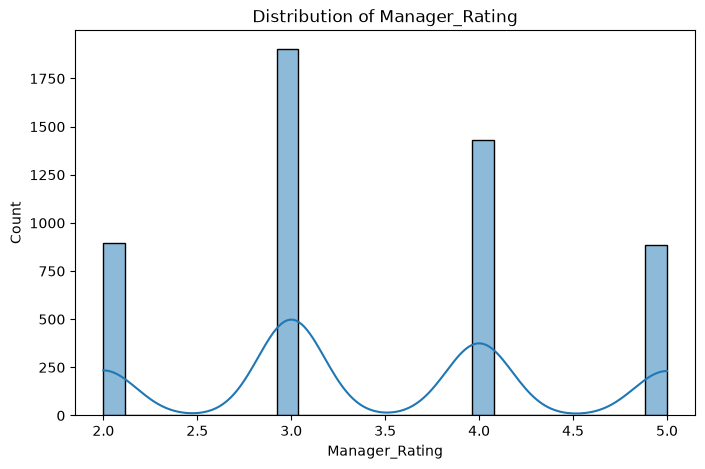

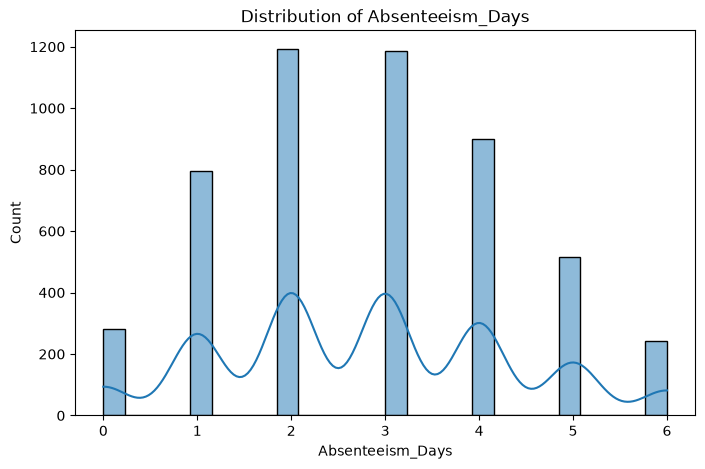

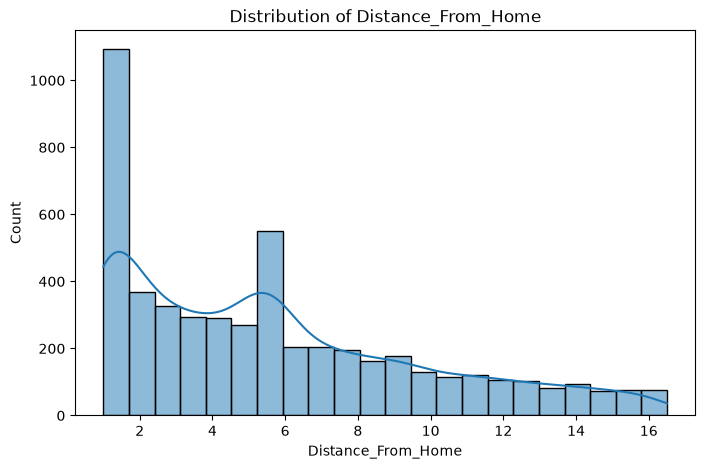

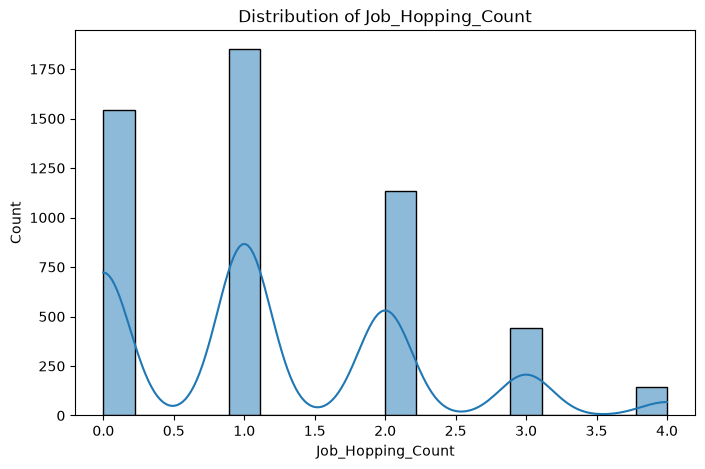

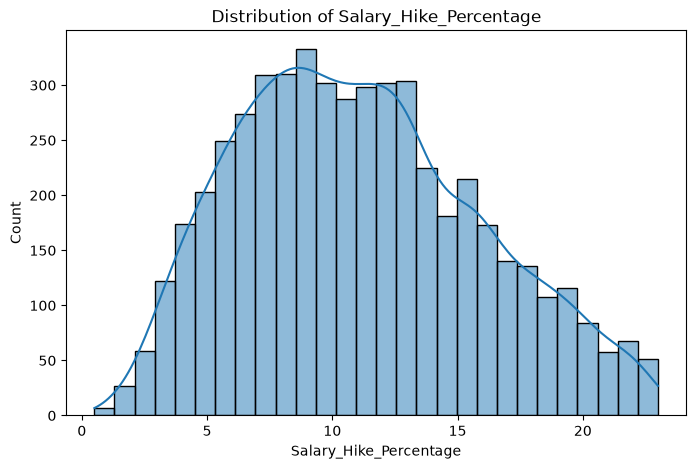

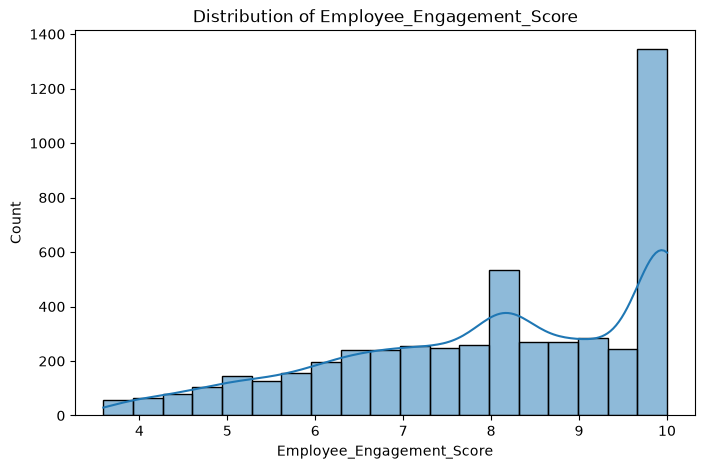

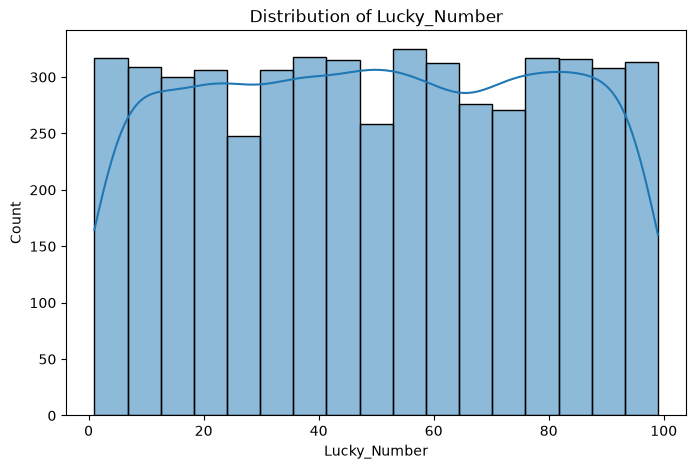

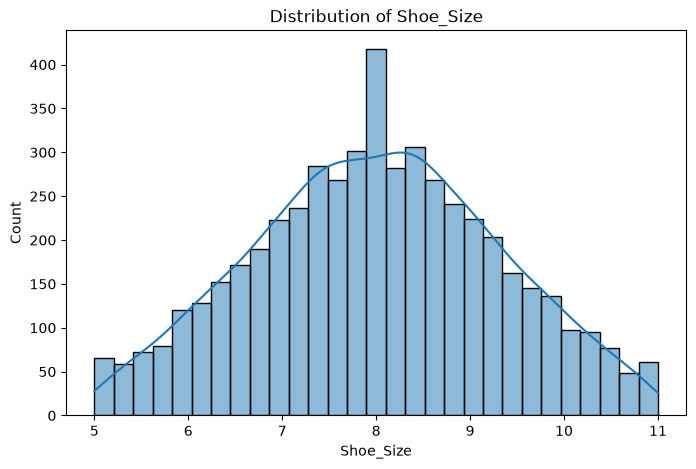

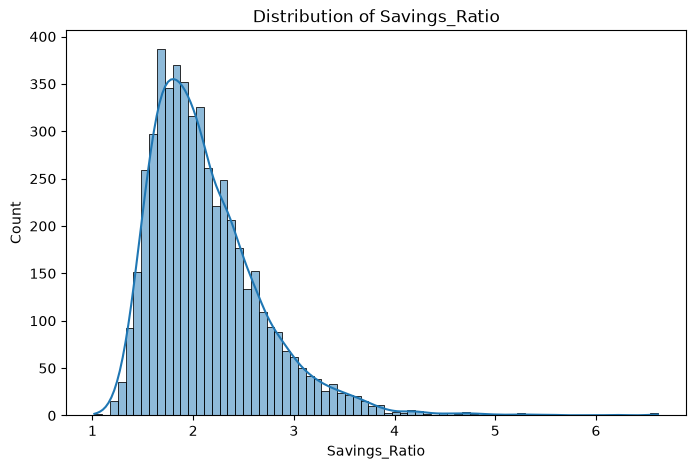

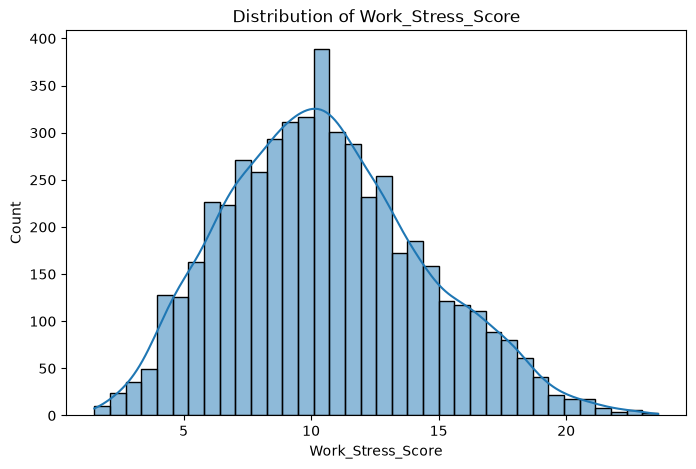

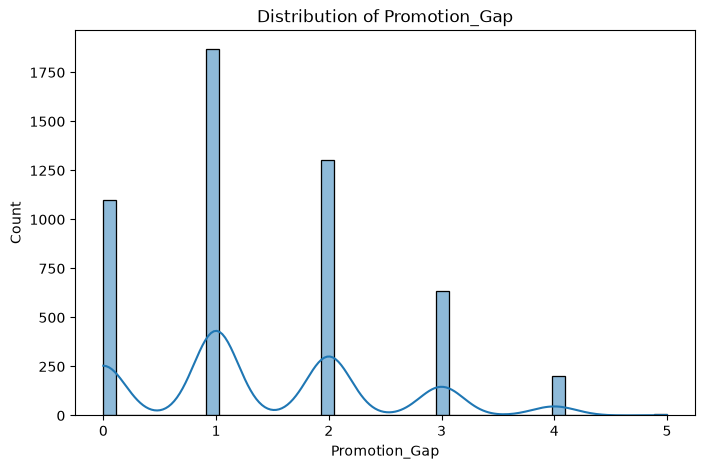

In [59]:
for col in num_cols:
    plt.figure(figsize=(8,5))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

In [60]:
high_skew= skew_values[abs(skew_values)>1]
print(high_skew)

Savings_Ratio    1.724608
dtype: float64


#abs=turn any number to positive

In [61]:
df["Savings_Ratio"]=np.log1p(df["Savings_Ratio"])

In [62]:
print("\nSkewness after log transformation:")
print(df["Savings_Ratio"].skew())


Skewness after log transformation:
0.8919851717026437


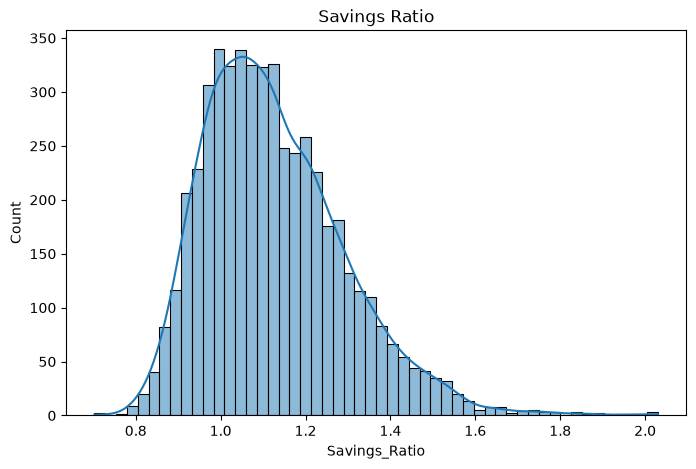

In [63]:
plt.figure(figsize=(8,5))
sns.histplot(df['Savings_Ratio'], kde=True)
plt.title("Savings Ratio")
plt.show()

## ENCODING

In [64]:
!pip install scikit-learn


In [65]:
for col in df.select_dtypes(include='object').columns:
    df[col]=df[col].fillna(df[col].mode()[0])

C:\Users\USER\AppData\Local\Temp\ipykernel_10308\4124050719.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [66]:
df

,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,...,Salary_Hike_Percentage,Employee_Engagement_Score,Favorite_Color,Lucky_Number,Shoe_Size,Commute_Mode,Attrition,Savings_Ratio,Work_Stress_Score,Promotion_Gap
0,100405,40,Male,Single,Bachelor,IT,System Admin,1,0,0,...,1.9,7.94,White,35,9.7,Bike,No,1.001245,9.5,1
3,107337,50,Female,Married,Master,R&D,Research Scientist,1,1,1,...,3.9,5.24,Green,27,6.9,Car,Yes,1.119401,11.0,0
10,105018,30,Male,Single,Bachelor,IT,IT Manager,3,2,1,...,8.0,8.29,White,57,7.6,Walk,No,1.171966,14.4,2
12,104702,31,Female,Divorced,Master,IT,System Admin,1,1,0,...,7.7,6.94,Green,59,8.6,Car,No,1.065591,8.4,1
13,108549,36,Female,Married,Bachelor,IT,Data Analyst,0,0,0,...,9.9,7.01,White,62,8.7,Bike,No,1.025833,6.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14981,103240,25,Female,Single,Bachelor,HR,HR Manager,2,1,0,...,19.4,9.03,Green,23,9.3,Car,No,0.988160,4.7,2
14982,113193,35,Male,Married,Bachelor,Sales,Sales Representative,3,2,1,...,3.5,9.06,Blue,96,6.3,Public Transport,No,1.017875,11.7,2
14986,104442,18,Female,Single,High School,IT,Software Engineer,0,0,0,...,15.3,5.79,Red,20,9.7,Public Transport,Yes,1.106089,12.6,0
14988,102584,38,Male,Single,Master,Sales,Sales Representative,2,2,1,...,6.9,5.98,Black,59,5.4,Public Transport,Yes,1.073933,7.3,1


In [67]:
df['Gender'] = LabelEncoder().fit_transform(df['Gender'])
df['Attrition'] = LabelEncoder().fit_transform(df['Attrition']) 


In [68]:
df['Gender']

0        1
3        0
10       1
12       0
13       0
        ..
14981    0
14982    1
14986    0
14988    1
14993    1
Name: Gender, Length: 5115, dtype: int64

In [69]:
df['Attrition']

0        0
3        1
10       0
12       0
13       0
        ..
14981    0
14982    0
14986    1
14988    1
14993    0
Name: Attrition, Length: 5115, dtype: int64

#ordinal Encodeing

In [70]:
education_order={'High School':1, 'Diploma':2, 'Bachelor':3, 'Master':4, 'PhD':5}
df["Education_Level"] = df["Education_Level"].map(education_order)

In [71]:
df['Education_Level'].unique()

array([3, 4, 1, 5])

In [72]:
df.isnull().sum()

Employee_ID                   0
Age                           0
Gender                        0
Marital_Status                0
Education_Level               0
Department                    0
Job_Role                      0
Years_at_Company              0
Years_in_Current_Role         0
Years_Since_Last_Promotion    0
Monthly_Income                0
Monthly_Expenses              0
Job_Satisfaction              0
Work_Life_Balance             0
Performance_Rating            0
Training_Hours                0
Overtime_Hours                0
Remote_Work_Days              0
Number_of_Projects            0
Manager_Rating                0
Absenteeism_Days              0
Distance_From_Home            0
Job_Hopping_Count             0
Salary_Hike_Percentage        0
Employee_Engagement_Score     0
Favorite_Color                0
Lucky_Number                  0
Shoe_Size                     0
Commute_Mode                  0
Attrition                     0
Savings_Ratio                 0
Work_Str

One-Hot Encoding

In [73]:
df=pd.get_dummies(
    df,
    columns=[
        'Department',
        'Job_Role',
        'Marital_Status',
        'Commute_Mode',
        'Favorite_Color'
    ],
    drop_first=True,
    dtype=int)


In [74]:
df

,Employee_ID,Age,Gender,Education_Level,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Monthly_Income,Monthly_Expenses,Job_Satisfaction,...,Marital_Status_Married,Marital_Status_Single,Commute_Mode_Car,Commute_Mode_Public Transport,Commute_Mode_Walk,Favorite_Color_Blue,Favorite_Color_Green,Favorite_Color_Red,Favorite_Color_White,Favorite_Color_Yellow
0,100405,40,1,3,1,0,0,31311.30,18186.60,3.0,...,0,1,0,0,0,0,0,0,1,0
3,107337,50,0,4,1,1,1,40918.98,19834.51,2.0,...,1,0,1,0,0,0,1,0,0,0
10,105018,30,1,3,3,2,1,44306.30,19883.17,2.0,...,0,1,0,0,1,0,0,0,1,0
12,104702,31,0,4,1,1,0,35299.17,18553.57,3.0,...,0,0,1,0,0,0,1,0,0,0
13,108549,36,0,3,0,0,0,23894.68,13353.32,2.0,...,1,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14981,103240,25,0,3,2,1,0,26054.16,15450.61,3.0,...,0,1,1,0,0,0,1,0,0,0
14982,113193,35,1,3,3,2,1,38947.53,22037.76,2.0,...,1,0,0,1,0,1,0,0,0,0
14986,104442,18,0,1,0,0,0,20408.40,10090.61,3.0,...,0,1,0,1,0,0,0,1,0,0
14988,102584,38,1,4,2,2,1,34038.90,17665.41,2.0,...,0,1,0,1,0,0,0,0,0,0


In [75]:
df['Job_Satisfaction']

0        3.0
3        2.0
10       2.0
12       3.0
13       2.0
        ... 
14981    3.0
14982    2.0
14986    3.0
14988    2.0
14993    4.0
Name: Job_Satisfaction, Length: 5115, dtype: float64

In [76]:
df.shape

(5115, 61)

In [77]:
df.info()

<class 'pandas.DataFrame'>
Index: 5115 entries, 0 to 14993
Data columns (total 61 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Employee_ID                     5115 non-null   int64  
 1   Age                             5115 non-null   int64  
 2   Gender                          5115 non-null   int64  
 3   Education_Level                 5115 non-null   int64  
 4   Years_at_Company                5115 non-null   int64  
 5   Years_in_Current_Role           5115 non-null   int64  
 6   Years_Since_Last_Promotion      5115 non-null   int64  
 7   Monthly_Income                  5115 non-null   float64
 8   Monthly_Expenses                5115 non-null   float64
 9   Job_Satisfaction                5115 non-null   float64
 10  Work_Life_Balance               5115 non-null   float64
 11  Performance_Rating              5115 non-null   int64  
 12  Training_Hours                  5115 non-null   f

## CORRELATION

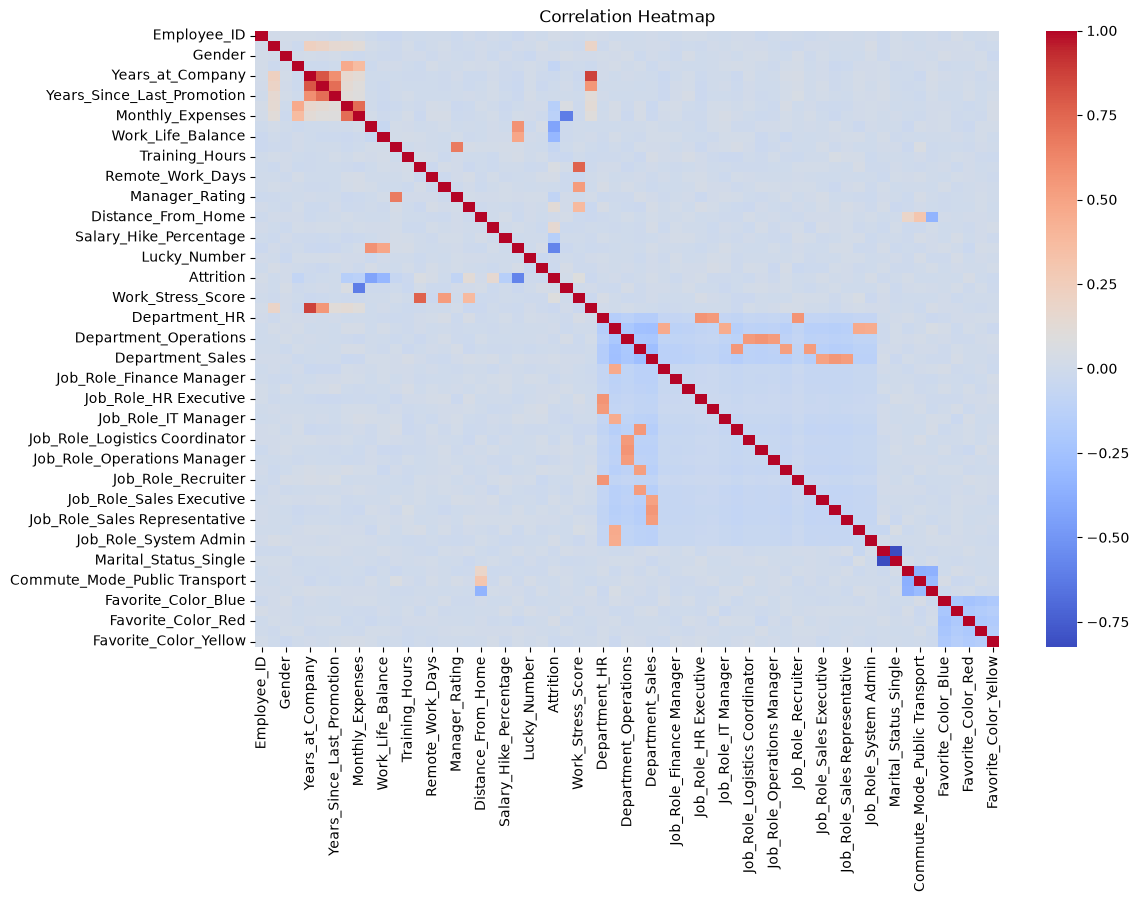

In [78]:
numeric_df=df.select_dtypes(include=['int64','float64'])
plt.figure(figsize=(12,8))
sns.heatmap(numeric_df.corr(),
cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

depend variable-output
independent variable-input

In [79]:
target_corr=df.corr(numeric_only=True)['Attrition'].abs()
target_corr.sort_values(ascending=False)

Attrition                    1.000000
Employee_Engagement_Score    0.582961
Job_Satisfaction             0.428899
Work_Life_Balance            0.323650
Job_Hopping_Count            0.152127
                               ...   
Job_Role_Sales Manager       0.001564
Job_Role_Data Analyst        0.000746
Department_HR                0.000485
Department_R&D               0.000310
Marital_Status_Single        0.000137
Name: Attrition, Length: 61, dtype: float64

# 7.Feature Selection

select all the x 

In [80]:
x = df[[
    'Education_Level',
    'Monthly_Income',
    'Monthly_Expenses',
    'Job_Satisfaction',
    'Work_Life_Balance',
    'Performance_Rating',
    'Overtime_Hours',
    'Manager_Rating',
    'Absenteeism_Days',
    'Job_Hopping_Count',
    'Salary_Hike_Percentage',
    'Employee_Engagement_Score',
    'Work_Stress_Score'
]]
y=df['Attrition']

# Train-Test-Split

In [81]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42)

#scaling 1.min max scaling 2.standard scaling

# Smote

changing unbalanced data to balanced data

smote is used for oversampling

In [82]:
!pip install imbalanced-learn

In [83]:

sm = SMOTE(random_state=42)
x_train_smote, y_train_smote = sm.fit_resample(x_train, y_train)

# Model Training


In [84]:
model=RandomForestClassifier(
    n_estimators=300,
    random_state=42
)
model.fit(x_train,y_train)
pred=model.predict(x_test)


# Evaluation

In [85]:
print('Accuracy:', accuracy_score(y_test, pred))
print('Precision:', precision_score(y_test, pred))
print('Recall:', recall_score(y_test, pred))
print('F1 Score:', f1_score(y_test, pred))

Accuracy: 0.9286412512218963
Precision: 0.8639455782312925
Recall: 0.7055555555555556
F1 Score: 0.7767584097859327


In [88]:
df.head()

,Employee_ID,Age,Gender,Education_Level,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Monthly_Income,Monthly_Expenses,Job_Satisfaction,...,Marital_Status_Married,Marital_Status_Single,Commute_Mode_Car,Commute_Mode_Public Transport,Commute_Mode_Walk,Favorite_Color_Blue,Favorite_Color_Green,Favorite_Color_Red,Favorite_Color_White,Favorite_Color_Yellow
0,100405,40,1,3,1,0,0,31311.30,18186.60,3.0,...,0,1,0,0,0,0,0,0,1,0
3,107337,50,0,4,1,1,1,40918.98,19834.51,2.0,...,1,0,1,0,0,0,1,0,0,0
10,105018,30,1,3,3,2,1,44306.30,19883.17,2.0,...,0,1,0,0,1,0,0,0,1,0
12,104702,31,0,4,1,1,0,35299.17,18553.57,3.0,...,0,0,1,0,0,0,1,0,0,0
13,108549,36,0,3,0,0,0,23894.68,13353.32,2.0,...,1,0,0,0,0,0,0,0,1,0


In [86]:
import pandas as pd

# User Inputs (only for features used in the final model)
education_level = int(input("Enter Education Level: "))
monthly_income = float(input("Enter Monthly Income: "))
monthly_expenses = float(input("Enter Monthly Expenses: "))
job_satisfaction = float(input("Enter Job Satisfaction (1-5): "))
work_life_balance = float(input("Enter Work Life Balance (1-5): "))
performance_rating = int(input("Enter Performance Rating: "))
overtime_hours = float(input("Enter Overtime Hours: "))
manager_rating = float(input("Enter Manager Rating: "))
absenteeism_days = int(input("Enter Absenteeism Days: "))
job_hopping_count = int(input("Enter Job Hopping Count: "))
salary_hike_percentage = float(input("Enter Salary Hike Percentage: "))
employee_engagement_score = float(input("Enter Employee Engagement Score: "))
Work_Stress_Score = float(input("Enter Work Stress Score: "))

# Create DataFrame with only the selected features
new_employee = pd.DataFrame({
    'Education_Level': [education_level],
    'Monthly_Income': [monthly_income],
    'Monthly_Expenses': [monthly_expenses],
    'Job_Satisfaction': [job_satisfaction],
    'Work_Life_Balance': [work_life_balance],
    'Performance_Rating': [performance_rating],
    'Overtime_Hours': [overtime_hours],
    'Manager_Rating': [manager_rating],
    'Absenteeism_Days': [absenteeism_days],
    'Job_Hopping_Count': [job_hopping_count],
    'Salary_Hike_Percentage': [salary_hike_percentage],
    'Employee_Engagement_Score': [employee_engagement_score],
    'Work_Stress_Score': [Work_Stress_Score]
})

# Prediction
prediction = model.predict(new_employee)

if prediction[0] == 1:
    print("\nEmployee is likely to leave the company.")
else:
    print("\nEmployee is likely to stay in the company.")


Employee is likely to stay in the company.


In [87]:
import pickle
with open ('employee_attrition_model.pkl',"wb")as f:
    pickle.dump(model,f)
print("Model saved sucessfully")    

Model saved sucessfully


# ------------------DOCUMENTATION----------------

Employee Attrition Prediction
Project Workflow

Problem Statement → Data Understanding → Data Cleaning → Data Visualization → Outlier Handling → Feature Engineering → Skewness Handling → Encoding → Correlation → Feature Selection → Train-Test Split → Scaling → SMOTE → Model Training → Model Evaluation → Deployment

1. Problem Statement

Employee attrition refers to employees leaving an organization. The objective of this project is to analyze employee data and develop a machine learning model to predict employee attrition.

2. Data Understanding

The dataset is examined to understand its structure, features, data types, and important employee attributes.

3. Data Cleaning

Missing values, duplicate records, incorrect values, and unnecessary data are identified and handled.

4. Data Visualization

Graphs and charts are used to understand data patterns and relationships between employee attributes and attrition.

5. Outlier Handling

Unusual or extreme values are identified and appropriately handled to improve data quality.

6. Feature Engineering

Existing features are transformed or new features are created to provide useful information for the machine learning model.

7. Skewness Handling

Highly skewed numerical features are identified and suitable transformations are applied when necessary.

8. Encoding

Categorical variables are converted into numerical form so they can be used by machine learning algorithms.

9. Correlation

Correlation analysis is performed to understand relationships between numerical features and identify strongly related variables.

10. Feature Selection

Relevant and useful features are selected for building the machine learning model.

11. Train-Test Split

The dataset is divided into training and testing data. The training data is used for model development and the testing data for evaluation.

12. Scaling

Numerical features are scaled to bring them to a comparable range, particularly for algorithms sensitive to feature magnitude.

13. SMOTE

SMOTE is applied to the training data when the attrition classes are imbalanced. It helps balance the minority class by generating synthetic samples.

14. Model Training

A machine learning classification algorithm is trained using the prepared training data to predict employee attrition.

15. Model Evaluation

The model is evaluated using metrics such as accuracy, precision, recall, F1-score, and confusion matrix.

16. Deployment

The trained model is deployed as an application or system that can accept new employee information and provide an attrition prediction.